# CAMM Hackathon 13: Two Previous Problems Revisited with Agents

In this notebook we revisit two problems from earlier CAMM hackathons and suggest solving them again, but this time with an **agentic approach**.

## What is an agent?

For this hackathon, an agent is an LLM-based system that can **plan**, **use tools**, **inspect intermediate results**, and **iterate** toward a goal instead of producing only one direct answer.

A simple agent loop is:

1. observe the current state
2. decide what to do next
3. call a tool or run code
4. evaluate the result
5. revise the plan if needed

## Good starting references

- Anthropic, [Building Effective Agents](https://www.anthropic.com/engineering/building-effective-agents)
- OpenAI, [A Practical Guide to Building AI Agents](https://openai.com/business/guides-and-resources/a-practical-guide-to-building-ai-agents/)


In [1]:
!pip install gpytorch


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 291.2/291.2 kB 8.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 174.8/174.8 kB 5.7 MB/s eta 0:00:00


In [2]:
from pathlib import Path

import h5py
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.ndimage import binary_dilation
from skimage.draw import line as draw_line


## Problem 1: STEM Image Restoration

This problem comes from [**CAMM Hackathon #10**](https://github.com/kbarakati/camm_hackathon/blob/k4my4r/docs/day_10_27032026/CAMM_hackaton_10_Image_Restoration.ipynb).

**Task:** given a 2D microscopy intensity image and a binary loss mask, reconstruct the missing regions and estimate uncertainty.


In [ ]:
image_files = {
    "graphene_2.h5": "14N5Vg7Baqj2OdvgTD1l9oaWWvNvPCpYs",
    "HAADF_21.h5": "1IB2Au4Dh7iNZCeOmj1dmaGB2JOIFAxoN",
}

for filename, file_id in image_files.items():
    if not Path(filename).exists():
        !gdown {file_id} -O "{filename}"
    else:
        print(f"Using existing file: {filename}")


Using existing file: graphene_2.h5
Using existing file: HAADF_21.h5


In [ ]:
import json


def load_hdf5_to_dict(file_path):
    with h5py.File(file_path, "r") as f:
        return _load_item(f)


def _load_item(obj):
    if isinstance(obj, h5py.Group):
        keys = list(obj.keys())
        if len(keys) == 0 and "value" not in obj.attrs:
            return {}
        if all(k.isdigit() for k in keys):
            return [_load_item(obj[k]) for k in sorted(keys, key=lambda x: int(x))]
        out = {k: _load_item(obj[k]) for k in keys}
        if "value" in obj.attrs and obj.attrs["value"] == "None":
            return None
        return out

    if isinstance(obj, h5py.Dataset):
        data = obj[()]
        if np.isscalar(data):
            return data
        if isinstance(data, (bytes, np.bytes_)):
            try:
                return json.loads(data.decode())
            except Exception:
                return data.decode()
        if getattr(data, "dtype", None) is not None and data.dtype.kind == "S":
            try:
                return [json.loads(x.decode()) for x in data]
            except Exception:
                return [x.decode() for x in data]
        return data

    raise ValueError(f"Unknown HDF5 object type: {type(obj)}")


def mask_below_line(im, frac=0.6, above=True):
    h, w = im.shape
    row = int(frac * h)
    mask = np.zeros((h, w), dtype=bool)
    mask[:row, :] = True if above else False
    mask[row:, :] = False if above else True
    return mask


def mask_lines(im, n_lines=80, thickness=4, orientation="horizontal", seed=0):
    rng = np.random.default_rng(seed)
    h, w = im.shape
    mask = np.zeros((h, w), dtype=bool)
    orientations = ["horizontal", "vertical", "diagonal"]

    for _ in range(n_lines):
        ort = rng.choice(orientations) if orientation == "mixed" else orientation
        if ort == "horizontal":
            mask[rng.integers(0, h), :] = True
        elif ort == "vertical":
            mask[:, rng.integers(0, w)] = True
        else:
            r0, c0 = rng.integers(0, h), rng.integers(0, w)
            r1, c1 = rng.integers(0, h), rng.integers(0, w)
            rr, cc = draw_line(r0, c0, r1, c1)
            valid = (rr >= 0) & (rr < h) & (cc >= 0) & (cc < w)
            mask[rr[valid], cc[valid]] = True

    if thickness > 1:
        mask = binary_dilation(mask, structure=np.ones((thickness, thickness), dtype=bool))
    return ~mask


In [ ]:
data = load_hdf5_to_dict("graphene_2.h5")
data_more = load_hdf5_to_dict("HAADF_21.h5")

im0 = data["Measurement_000"]["Channel_000"]["HAADF"]["HAADF"][:1000, :1000]
im1 = data["Measurement_001"]["Channel_000"]["HAADF"]["HAADF"][:1000, :1000]
im2 = data["Measurement_001"]["Channel_000"]["HAADF"]["HAADF"][:1000, -1000:]
im3 = data_more["Measurement_000"]["Channel_000"]["HAADF"]["HAADF"]

ims = [im0, im1, im2, im3]


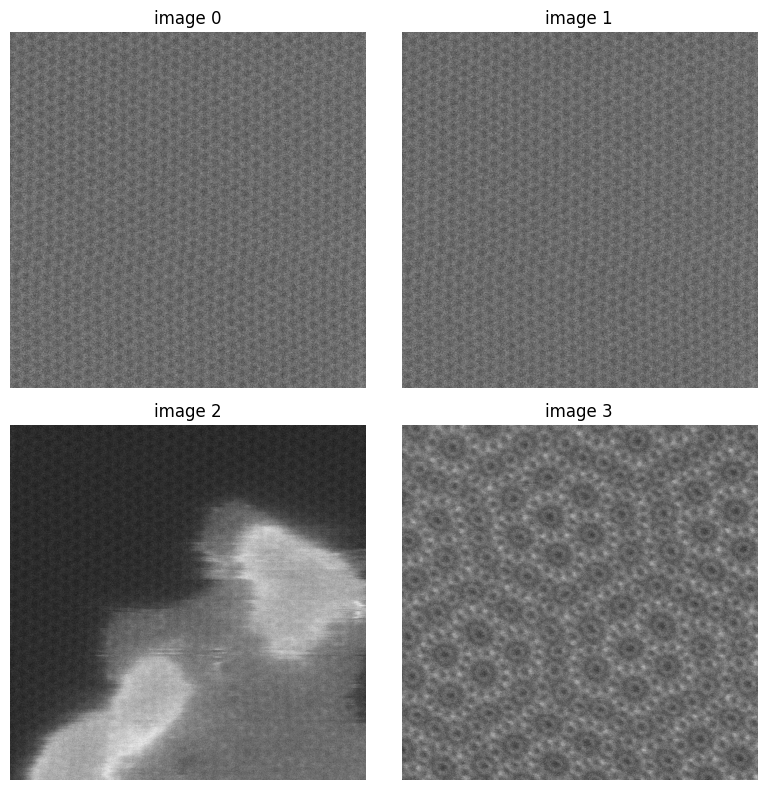

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(8, 8))
for i, ax in enumerate(axes.flat):
    ax.imshow(ims[i], cmap="gray")
    ax.set_title(f"image {i}")
    ax.axis("off")
plt.tight_layout()
plt.show()


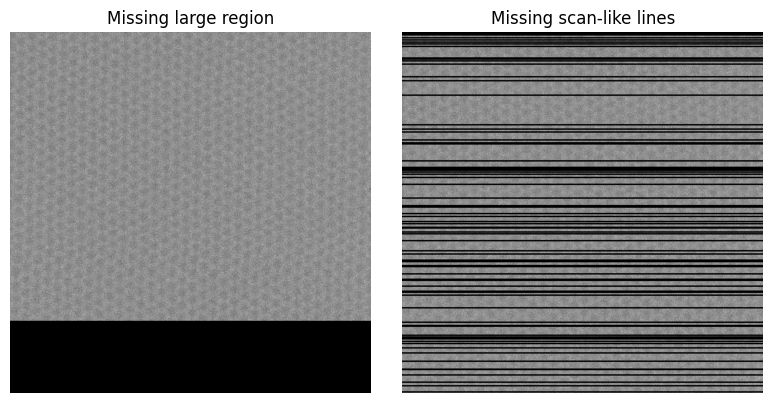

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(8, 4))
ax[0].imshow(mask_below_line(im0, frac=0.8) * im0, cmap="gray")
ax[0].set_title("Missing large region")
ax[0].axis("off")

ax[1].imshow(mask_lines(im0, seed=0) * im0, cmap="gray")
ax[1].set_title("Missing scan-like lines")
ax[1].axis("off")
plt.tight_layout()
plt.show()


### Can we design an agent which will design and execute uncertanty aware image reconstruction framework?

## Problem 2: Active Experimental Design under Noise and Budget Constraints

This problem comes from [**CAMM Hackathon #11**](https://github.com/kbarakati/camm_hackathon/blob/k4my4r/docs/day_11_10042026/CAMM_Hackaton_11.ipynb).

**Task:** design a strategy that decides **where to measure**, **in what order**, and **for how long**, while accounting for measurement noise, limited budget, and movement cost.


### Minimal starter setup

The general setup cell above already installs the required packages. The cells below give a lightweight starting point for testing an adaptive measurement strategy.


In [3]:
import numpy as np
import matplotlib.pyplot as plt
import gpytorch


In [52]:
# Example target functions for testing your strategy

def unimodal(x):
    return 1.2 * np.exp(-0.5 * ((x - 2.3) / 0.7) ** 2) + 0.1


def oscillatory(x):
    return 0.55 + 0.15 * np.sin(1.8 * x) + 0.08 * np.cos(6.0 * x)

def multimodal(x):
    x = np.asarray(x)
    res = 10 + x**2 - 7 * np.cos(2 * np.pi * x) + 9 * np.sin(1.4 * np.pi * x)
    return res/40


def double_well(x):
    x = np.asarray(x)
    res = 0.08 * (x**2 - 7)**2 + 0.45 * x

    return res/10

def broad_narrow(x):
    x = np.asarray(x)

    res = (
        1
        - 1.0 * np.exp(-((x - 2.5)**2) / (2 * 0.9**2))
        - 1.6 * np.exp(-((x - 1.0)**2) / (2 * 0.08**2))
    )
    return -res


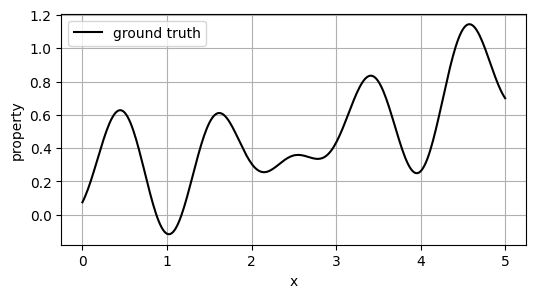

In [5]:
x_grid = np.linspace(0, 5, 300)
f_true = multimodal

plt.figure(figsize=(6, 3))
plt.plot(x_grid, f_true(x_grid), 'k', label='ground truth')
plt.xlabel('x')
plt.ylabel('property')
plt.grid()
plt.legend()
plt.show()


In [6]:

#@title simple noise models

def noise_constant(x = None, t = None, sigma0=0.1):
    t = np.asarray(t)
    return sigma0 * np.ones_like(t, dtype=float)

def noise_decay_floor(x = None, t = None, sigma_min=0.05, A=0.18, tau=1.0):
    t = np.asarray(t)
    return sigma_min + A * np.exp(-t / tau)

In [7]:
# Simple budget accounting example
budget_total = 12.0
travel_weight = 0.15

# Example move from x=1.0 to x=3.5 with acquisition time 0.8
x_prev = 1.0
x_next = 3.5
acq_time = 0.8

travel_cost = travel_weight * abs(x_next - x_prev)
step_cost = acq_time + travel_cost
print('Example step cost:', round(step_cost, 3))
print('Remaining budget after step:', round(budget_total - step_cost, 3))


Example step cost: 1.175
Remaining budget after step: 10.825


In [8]:

#@title measurement simulator

class MeasurementSimulator:
    def __init__(self, ground_truth_model, noise_model, rng=None, **noise_kwargs):
        """
        Parameters
        ----------
        ground_truth_model : callable
            Function f(x)
        noise_model : callable
            Function sigma(x, t, **noise_kwargs)
        rng : None, int, or np.random.Generator
            Random generator or seed
        **noise_kwargs
            Default parameters for noise_model
        """
        self.f = ground_truth_model
        self.noise_model = noise_model
        self.noise_kwargs = noise_kwargs

        if rng is None:
            self.rng = np.random.default_rng()
        elif isinstance(rng, (int, np.integer)):
            self.rng = np.random.default_rng(rng)
        else:
            self.rng = rng

    def measure(self, coords, **noise_kwargs):
        """
        coords : array of shape (N, 2)
            Columns are (x, t)

        Returns
        -------
        y_meas : array of shape (N,)
            Noisy measurements
        """
        coords = np.asarray(coords, dtype=float)

        if coords.ndim != 2 or coords.shape[1] != 2:
            raise ValueError("coords must have shape (N, 2)")

        x = coords[:, 0]
        t = coords[:, 1]

        kwargs = {**self.noise_kwargs, **noise_kwargs}
        sigma = np.asarray(self.noise_model(x, t, **kwargs), dtype=float)
        noise = self.rng.normal(0.0, sigma, size=len(x))

        return self.f(x) + noise

    __call__ = measure

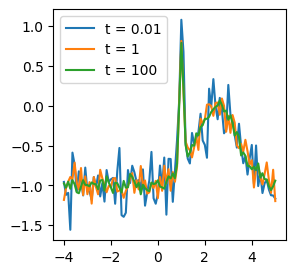

In [55]:

#@title example: grid measurements with different acqusition time

x = np.linspace(-4,5, 100) #x grid

durations = [0.01, 1, 100] #select durations
model = multimodal #select model [unimodal, double_well, multimodal, broad_narrow]


sim_decay = MeasurementSimulator(
    ground_truth_model=broad_narrow,
    noise_model=noise_decay_floor,
    rng=2,
)


fig, ax = plt.subplots(figsize=(3,3))

for d in durations:
  d_ar = np.ones(len(x))*d
  coords = np.vstack([x, d_ar]).T

  ax.plot(coords[:,0], sim_decay.measure(coords), label = f't = {d}')

ax.legend()

#### Can an agentic approach be useful for integration such experimental campaigns?

In [10]:

B = 200 #your budget (can be different)

meas_sim = MeasurementSimulator(
    ground_truth_model=broad_narrow, #choose gt function
    noise_model=noise_decay_floor,  #choose noise model
    rng=123,
)

In [11]:
#define x_grid on the explored interval

x_grid = np.linspace(0, 4, 500)

# For this example, select 4 random locations in the range (-4, 4)
x = np.random.random(7) * 8 - 4

# Set acquisition time (t = 3) for all locations
t = np.ones(len(x)) * 1

# Form the coordinate array: [[x1, t1], [x2, t2], ...]
coords = np.column_stack([x, t])




In [19]:
#@title step1_campaign.py
import numpy as np

class ExperimentalCampaign:
    """
    Wraps MeasurementSimulator and maintains the observation history
    for a 1D sequential campaign.

    The simulator expects coords of shape (N, 2) with columns (x, t).
    We call it one point at a time: t increments by 1 each step.
    """

    def __init__(self, simulator, x_bounds=(0.0, 1.0)):
        self.sim = simulator
        self.x_bounds = x_bounds

        # observation history
        self.X = []       # list of x values measured
        self.T = []       # list of t values (step index)
        self.Y = []       # list of noisy measurements
        self.t = 0        # current time step

    def measure(self, x: float) -> float:
        x = float(np.clip(x, *self.x_bounds))
        coord = np.array([[x, self.t]], dtype=float)
        y = float(self.sim.measure(coord).item())   # .item() extracts scalar safely
        self.X.append(x)
        self.T.append(self.t)
        self.Y.append(y)
        self.t += 1
        return y

    def observe_batch(self, xs) -> np.ndarray:
        """
        Measure a list of x values sequentially (t increments per point).
        Used for the initialization phase.
        """
        return np.array([self.measure(x) for x in xs])

    @property
    def observations(self):
        return (
            np.array(self.X),
            np.array(self.T),
            np.array(self.Y),
        )

    @property
    def best(self):
        if not self.Y:
            return None, None
        idx = int(np.argmax(self.Y))
        return self.X[idx], self.Y[idx]

    def summary(self) -> dict:
        X, T, Y = self.observations
        bx, by = self.best
        return {
            "n_obs": len(Y),
            "t_current": self.t,
            "best_x": round(bx, 4) if bx is not None else None,
            "best_y": round(float(by), 4) if by is not None else None,
            "y_mean": round(float(Y.mean()), 4) if len(Y) else None,
            "y_std": round(float(Y.std()), 4) if len(Y) else None,
        }

In [17]:
#@title step2_gp.py  (fixed)
import numpy as np
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import Matern, ConstantKernel, WhiteKernel, Sum, Product

class GPSurrogate:

    def __init__(self, window=50, length_scale=2.0, length_scale_bounds=(0.2, 10.0)):
        self.window = window
        self.length_scale_init = length_scale
        self.length_scale_bounds = length_scale_bounds
        self.gp = None
        self._build()

    def _build(self):
        kernel = (
            ConstantKernel(1.0, constant_value_bounds=(1e-3, 10.0))
            * Matern(
                length_scale=self.length_scale_init,
                length_scale_bounds=self.length_scale_bounds,
                nu=2.5,
            )
            + WhiteKernel(noise_level=0.1, noise_level_bounds=(1e-5, 2.0))
        )
        self.gp = GaussianProcessRegressor(
            kernel=kernel,
            n_restarts_optimizer=5,
            normalize_y=True,
        )

    def fit(self, X: np.ndarray, Y: np.ndarray):
        X = np.asarray(X).ravel()
        Y = np.asarray(Y).ravel()
        if len(X) > self.window:
            X = X[-self.window:]
            Y = Y[-self.window:]
        self.gp.fit(X.reshape(-1, 1), Y)

    def predict(self, x_grid: np.ndarray):
        mu, sigma = self.gp.predict(x_grid.reshape(-1, 1), return_std=True)
        return mu, sigma

    def _walk_kernel(self, k):
        """
        Recursively walk sklearn's kernel tree (Sum, Product, or leaf).
        Yields all leaf kernel objects.
        """
        if isinstance(k, (Sum, Product)):
            yield from self._walk_kernel(k.k1)
            yield from self._walk_kernel(k.k2)
        else:
            yield k

    @property
    def length_scale(self) -> float:
        for k in self._walk_kernel(self.gp.kernel_):
            if isinstance(k, Matern):
                return float(k.length_scale)
        return float('nan')

    @property
    def noise_level(self) -> float:
        for k in self._walk_kernel(self.gp.kernel_):
            if isinstance(k, WhiteKernel):
                return float(k.noise_level)
        return float('nan')

    def diagnostics(self) -> dict:
        return {
            "length_scale": round(self.length_scale, 4),
            "noise_level":  round(self.noise_level, 6),
            "log_marginal_likelihood": round(
                float(self.gp.log_marginal_likelihood_value_), 4
            ),
        }

    def rebuild(self, length_scale=None, window=None):
        if length_scale is not None:
            self.length_scale_init = length_scale
        if window is not None:
            self.window = window
        self._build()

In [20]:
#@title step3_acquisition.py
import numpy as np
from scipy.stats import norm
from scipy.optimize import minimize_scalar


class AcquisitionFunction:

    def __init__(self, x_bounds=(-5.0, 5.0), n_grid=500):
        self.x_bounds = x_bounds
        self.n_grid = n_grid

    def ucb(self, mu, sigma, beta=2.0):
        return mu + beta * sigma

    def ei(self, mu, sigma, best_y, xi=0.01):
        z = (mu - best_y - xi) / (sigma + 1e-9)
        return (mu - best_y - xi) * norm.cdf(z) + sigma * norm.pdf(z)

    def pi(self, mu, sigma, best_y, xi=0.01):
        z = (mu - best_y - xi) / (sigma + 1e-9)
        return norm.cdf(z)

    def propose(
        self,
        gp,
        strategy: str = "ucb",
        best_y: float = 0.0,
        beta: float = 2.0,
        xi: float = 0.01,
    ) -> tuple[float, dict]:

        x_grid = np.linspace(*self.x_bounds, self.n_grid)
        mu, sigma = gp.predict(x_grid)

        if strategy == "ucb":
            acq = self.ucb(mu, sigma, beta=beta)
        elif strategy == "ei":
            acq = self.ei(mu, sigma, best_y=best_y, xi=xi)
        elif strategy == "pi":
            acq = self.pi(mu, sigma, best_y=best_y, xi=xi)
        elif strategy == "sigma":
            acq = sigma
        else:
            raise ValueError(f"Unknown strategy: {strategy}")

        best_idx = int(np.argmax(acq))
        x_coarse = x_grid[best_idx]

        half_w = (self.x_bounds[1] - self.x_bounds[0]) / self.n_grid * 10
        lo = max(self.x_bounds[0], x_coarse - half_w)
        hi = min(self.x_bounds[1], x_coarse + half_w)

        def neg_acq(x):                                      # defined inside propose
            m, s = gp.predict(np.array([x]))
            m, s = float(m.item()), float(s.item())          # safe scalar extraction
            if strategy == "ucb":
                return -float(self.ucb(m, s, beta=beta))
            elif strategy == "ei":
                return -float(self.ei(m, s, best_y=best_y, xi=xi))
            elif strategy == "pi":
                return -float(self.pi(m, s, best_y=best_y, xi=xi))
            return -s

        result = minimize_scalar(neg_acq, bounds=(lo, hi), method="bounded")
        x_next = float(result.x) if result.success else x_coarse

        info = {
            "x_grid": x_grid,
            "mu": mu,
            "sigma": sigma,
            "acq": acq,
            "strategy": strategy,
            "beta": beta,
            "acq_at_x_next": float(-result.fun) if result.success else float(acq[best_idx]),
        }

        return x_next, info

In [21]:
#@title integration_check.py
import numpy as np

# assumes sim_decay already defined in your notebook
campaign = ExperimentalCampaign(sim_decay, x_bounds=(-5.0, 5.0))
gp       = GPSurrogate(window=50, length_scale=2.0)
acq      = AcquisitionFunction(x_bounds=(-5.0, 5.0))

# 5-point LHS init
from scipy.stats.qmc import LatinHypercube
sampler = LatinHypercube(d=1, seed=0)
xs_init = sampler.random(5) * 10 - 5   # scale [0,1] → [-5,5]
campaign.observe_batch(xs_init.ravel())

# one GP fit + proposal
X, T, Y = campaign.observations
gp.fit(X, Y)
x_next, info = acq.propose(gp, strategy="ucb", best_y=campaign.best[1])

print("diagnostics :", gp.diagnostics())
print("next x      :", round(x_next, 4))
print("acq value   :", round(info["acq_at_x_next"], 4))
print("campaign    :", campaign.summary())

diagnostics : {'length_scale': 0.2956, 'noise_level': 0.027705, 'log_marginal_likelihood': -7.0947}
next x      : -3.9539
acq value   : 1.0177
campaign    : {'n_obs': 5, 't_current': 5, 'best_x': -4.2739, 'best_y': 0.838, 'y_mean': 0.6819, 'y_std': 0.1486}


In [34]:
#@title step4_bo_loop.py
import numpy as np
from dataclasses import dataclass, field
from typing import Optional


@dataclass
class LoopState:
    """Snapshot passed to the agent at each inspection point."""
    step: int
    best_x: float
    best_y: float
    recent_residuals: list[float]   # |y - mu_GP| for last N steps
    length_scale_history: list[float]
    noise_level_history: list[float]
    current_strategy: str
    current_beta: float
    current_window: int
    budget_remaining: int


class BOLoop:
    """
    Inner BO loop. Owns the step counter and orchestrates:
        campaign → gp → acquisition → campaign (measure)

    Agent hooks
    -----------
    Every `agent_every` steps, or when a trigger fires,
    `agent_callback(state: LoopState) -> dict` is called.
    The returned dict may contain any of:
        "strategy"   : str    – switch acquisition strategy
        "beta"       : float  – change UCB beta
        "window"     : int    – change GP sliding window
        "length_scale": float – rebuild GP kernel with new prior
        "stop"       : bool   – terminate loop early
        "message"    : str    – logged as agent reasoning
    """

    def __init__(
        self,
        campaign,
        gp,
        acquisition,
        budget: int = 50,
        n_init: int = 8,
        agent_every: int = 10,
        agent_callback=None,
        # trigger thresholds
        residual_trigger: float = 3.0,   # sigma multiples
        lengthscale_trigger: float = 0.5, # fractional change
        plateau_steps: int = 8,           # steps without improvement
        verbose: bool = True,
    ):
        self.campaign = campaign
        self.gp = gp
        self.acq = acquisition
        self.budget = budget
        self.n_init = n_init
        self.agent_every = agent_every
        self.agent_callback = agent_callback

        self.residual_trigger = residual_trigger
        self.lengthscale_trigger = lengthscale_trigger
        self.plateau_steps = plateau_steps
        self.verbose = verbose

        # mutable loop state
        self.strategy = "ucb"
        self.beta = 2.0
        self.xi = 0.01

        # diagnostic histories
        self.residual_history: list[float] = []
        self.length_scale_history: list[float] = []
        self.noise_level_history: list[float] = []
        self.best_y_history: list[float] = []
        self.agent_log: list[dict] = []

        self.viz = LiveVisualizer(x_bounds=campaign.x_bounds)

    # ------------------------------------------------------------------
    # initialization
    # ------------------------------------------------------------------

    def _init_phase(self):
        """Latin hypercube over [-5, 5] with n_init points."""
        try:
            from scipy.stats.qmc import LatinHypercube
            sampler = LatinHypercube(d=1, seed=0)
            xs = sampler.random(self.n_init).ravel()
        except ImportError:
            xs = np.linspace(0, 1, self.n_init)

        lo, hi = self.campaign.x_bounds
        xs = xs * (hi - lo) + lo
        self.campaign.observe_batch(xs)
        self._log(f"init: {self.n_init} LHS points measured")

    # ------------------------------------------------------------------
    # trigger detection
    # ------------------------------------------------------------------

    def _check_triggers(self, mu_at_last: float, sigma_at_last: float) -> list[str]:
        triggers = []

        # 1. residual spike
        if len(self.residual_history) >= 1:
            last_residual = self.residual_history[-1]
            if last_residual > self.residual_trigger * sigma_at_last:
                triggers.append("residual_spike")

        # 2. lengthscale shift
        if len(self.length_scale_history) >= 5:
            recent = self.length_scale_history[-3:]
            earlier = self.length_scale_history[-6:-3]
            if earlier:
                frac = abs(np.mean(recent) - np.mean(earlier)) / (np.mean(earlier) + 1e-9)
                if frac > self.lengthscale_trigger:
                    triggers.append("lengthscale_shift")

        # 3. improvement plateau
        if len(self.best_y_history) >= self.plateau_steps:
            window = self.best_y_history[-self.plateau_steps:]
            if max(window) - min(window) < 1e-4:
                triggers.append("plateau")

        return triggers

    # ------------------------------------------------------------------
    # agent interface
    # ------------------------------------------------------------------

    def _call_agent(self, triggers: list[str]):
        if self.agent_callback is None:
            return

        X, T, Y = self.campaign.observations
        bx, by = self.campaign.best

        state = LoopState(
            step=self.campaign.t,
            best_x=round(float(bx), 4),
            best_y=round(float(by), 4),
            recent_residuals=[round(r, 4) for r in self.residual_history[-10:]],
            length_scale_history=[round(l, 4) for l in self.length_scale_history[-10:]],
            noise_level_history=[round(n, 6) for n in self.noise_level_history[-10:]],
            current_strategy=self.strategy,
            current_beta=self.beta,
            current_window=self.gp.window,
            budget_remaining=self.budget - self.campaign.t,
        )

        response = self.agent_callback(state, triggers)
        if response is None:
            return

        # apply agent decisions
        if "message" in response:
            self.agent_log.append({
                "step": self.campaign.t,
                "triggers": triggers,
                "message": response["message"],
            })
            self._log(f"[agent] {response['message']}")

        if response.get("strategy"):
            self.strategy = response["strategy"]
        if response.get("beta") is not None:
            self.beta = float(response["beta"])
        if response.get("window") is not None:
            self.gp.rebuild(window=int(response["window"]))
        if response.get("length_scale") is not None:
            self.gp.rebuild(length_scale=float(response["length_scale"]))
        if response.get("stop"):
            self._log("[agent] requested stop")
            raise StopIteration

    # ------------------------------------------------------------------
    # main loop
    # ------------------------------------------------------------------

    def run(self) -> dict:
        self._init_phase()

        steps_since_agent = 0

        try:
            while self.campaign.t < self.budget:
                X, T, Y = self.campaign.observations

                # fit GP
                self.gp.fit(X, Y)
                diag = self.gp.diagnostics()
                self.length_scale_history.append(diag["length_scale"])
                self.noise_level_history.append(diag["noise_level"])

                # propose next point
                _, by = self.campaign.best
                x_next, info = self.acq.propose(
                    self.gp,
                    strategy=self.strategy,
                    best_y=float(by),
                    beta=self.beta,
                    xi=self.xi,
                )
                info["x_next"] = x_next


                # measure
                y_new = self.campaign.measure(x_next)
                self.viz.update(self.campaign, self.gp, info, self.agent_log)

                # residual: compare to GP prediction before update
                mu_at_x, sigma_at_x = self.gp.predict(np.array([x_next]))
                residual = abs(float(y_new) - float(mu_at_x.item()))
                self.residual_history.append(residual)
                self.best_y_history.append(float(by))

                self._log(
                    f"t={self.campaign.t-1:3d} | x={x_next:+.3f} | "
                    f"y={y_new:+.4f} | μ={float(mu_at_x.item()):+.4f} | "
                    f"σ={float(sigma_at_x.item()):.4f} | "
                    f"ls={diag['length_scale']:.3f} | "
                    f"best={float(by):.4f}"
                )

                # trigger check
                triggers = self._check_triggers(
                    float(mu_at_x.item()), float(sigma_at_x.item())
                )
                steps_since_agent += 1

                if triggers or steps_since_agent >= self.agent_every:
                    if triggers:
                        self._log(f"triggers fired: {triggers}")
                    self._call_agent(triggers)
                    steps_since_agent = 0

        except StopIteration:
            pass

        return self._final_report()

    # ------------------------------------------------------------------
    # reporting
    # ------------------------------------------------------------------

    def _final_report(self) -> dict:
        bx, by = self.campaign.best
        return {
            "best_x": round(float(bx), 4),
            "best_y": round(float(by), 4),
            "n_obs": self.campaign.t,
            "agent_interventions": len(self.agent_log),
            "agent_log": self.agent_log,
            "length_scale_history": self.length_scale_history,
            "noise_level_history": self.noise_level_history,
            "residual_history": self.residual_history,
        }

    def _log(self, msg: str):
        if self.verbose:
            print(msg)

In [33]:
# smoke test — no agent yet
campaign = ExperimentalCampaign(sim_decay, x_bounds=(-5.0, 5.0))
gp       = GPSurrogate(window=50, length_scale=2.0)
acq      = AcquisitionFunction(x_bounds=(-5.0, 5.0))

loop = BOLoop(
    campaign=campaign,
    gp=gp,
    acquisition=acq,
    budget=30,
    n_init=8,
    agent_every=10,
    agent_callback=None,   # no agent yet
    verbose=True,
)

report = loop.run()
loop.viz.close()


init: 8 LHS points measured
t=  8 | x=+2.614 | y=+0.3375 | μ=+0.4390 | σ=0.1839 | ls=0.805 | best=0.5823
t=  9 | x=-5.000 | y=+0.7676 | μ=+0.4738 | σ=0.1497 | ls=0.636 | best=0.5823
t= 10 | x=-5.000 | y=+0.6275 | μ=+0.6541 | σ=0.1283 | ls=0.701 | best=0.7676
t= 11 | x=-5.000 | y=+0.7119 | μ=+0.6535 | σ=0.1080 | ls=0.712 | best=0.7676
t= 12 | x=-5.000 | y=+0.7092 | μ=+0.6826 | σ=0.0841 | ls=0.619 | best=0.7676
t= 13 | x=+1.109 | y=-0.1122 | μ=+0.4786 | σ=0.2018 | ls=0.565 | best=0.7676
t= 14 | x=+3.301 | y=+0.7644 | μ=+0.4440 | σ=0.2370 | ls=0.331 | best=0.7676
t= 15 | x=+3.094 | y=+0.4679 | μ=+0.6508 | σ=0.1614 | ls=0.379 | best=0.7676
t= 16 | x=+3.452 | y=+0.7853 | μ=+0.7385 | σ=0.1230 | ls=0.332 | best=0.7676
t= 17 | x=+5.000 | y=+0.7008 | μ=+0.4313 | σ=0.2828 | ls=0.389 | best=0.7853
t= 18 | x=-3.990 | y=+0.7066 | μ=+0.4478 | σ=0.2821 | ls=0.387 | best=0.7853
t= 19 | x=-3.640 | y=+0.7146 | μ=+0.5656 | σ=0.2354 | ls=0.382 | best=0.7853
t= 20 | x=-1.119 | y=+0.5258 | μ=+0.4364 | σ=0.2

AttributeError: 'BOLoop' object has no attribute 'viz'

In [25]:
!pip install anthropic

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 753.6/753.6 kB 20.4 MB/s eta 0:00:00


In [29]:
import os
os.environ["ANTHROPIC_API_KEY"] = "" #use yours

In [65]:
#@title step5_agent.py
import json
import anthropic

client = anthropic.Anthropic(api_key=os.environ["ANTHROPIC_API_KEY"])

SYSTEM_PROMPT = """You are an experiment planning agent controlling a Bayesian
optimization campaign over a 1D black-box function f(x), x in [-5, 5].

Your goal: help find the global maximum within the measurement budget.

You will receive the current campaign state and any diagnostic triggers.
You must always respond with a JSON object containing at least "strategy",
"beta", and "message".

Available parameters to change:
  "strategy"     : "ucb" | "ei" | "sigma"   (acquisition function)
  "beta"         : float  (UCB exploration weight, higher = more exploration)
  "window"       : int    (how many recent observations the GP uses)
  "length_scale" : float  (GP kernel length scale prior)
  "message"      : str    (your reasoning in 1-2 sentences)

What you know about the system:
- The domain is [-5, 5]. Early in the campaign the GP is uncertain everywhere.
- Length scale reflects the function's smoothness — if it shrinks, the GP is
  detecting fine local structure; if it grows, the landscape is flatter.
- High residuals mean the surrogate is surprised — the model is wrong somewhere.
- A plateau in best_y means the campaign is stuck, either locally or globally.
- Do not stay in a region if plato detectd - explore!
- Noise level reflects measurement noise — low noise means the GP is trustworthy.
- budget_remaining tells you how much you can still afford to explore.

You are not following fixed rules. You are reasoning about what is happening
in this particular campaign at this particular moment, and making a judgment
call about the best way to proceed given the evidence in front of you.

Respond ONLY with valid JSON, no markdown, no preamble.
"""


def agent_callback(state, triggers: list[str]) -> dict:
    """
    Called by BOLoop when a trigger fires or every N steps.
    Sends state + triggers to Claude, parses JSON response.
    """
    state_dict = {
        "step": state.step,
        "best_x": state.best_x,
        "best_y": state.best_y,
        "budget_remaining": state.budget_remaining,
        "triggers": triggers,
        "current_strategy": state.current_strategy,
        "current_beta": state.current_beta,
        "current_window": state.current_window,
        "recent_residuals": state.recent_residuals,
        "length_scale_history": state.length_scale_history,
        "noise_level_history": state.noise_level_history,
    }

    user_msg = json.dumps(state_dict, indent=2)

    response = client.messages.create(
        model="claude-opus-4-5",
        max_tokens=256,
        system=SYSTEM_PROMPT,
        messages=[{"role": "user", "content": user_msg}],
    )

    raw = response.content[0].text.strip()

    try:
        decision = json.loads(raw)
    except json.JSONDecodeError:
        # extract JSON if model added any surrounding text
        import re
        match = re.search(r'\{.*\}', raw, re.DOTALL)
        decision = json.loads(match.group()) if match else {}

    return decision

In [44]:
# step6_visualization.py
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from IPython.display import display, clear_output


# ── Live visualizer ──────────────────────────────────────────────────────────

class LiveVisualizer:
    """
    Call update() after each BO step to redraw the live plot inline.

    Shows:
      - Top:    true GP surrogate (mean ± 2σ) + observations + next point
      - Bottom: acquisition function landscape
    """

    def __init__(self, x_bounds=(-5.0, 5.0), n_grid=300):
        self.x_bounds = x_bounds
        self.x_grid = np.linspace(*x_bounds, n_grid)
        self.fig = None

    def _init_fig(self):
        self.fig, (self.ax_gp, self.ax_acq) = plt.subplots(
            2, 1, figsize=(10, 6),
            gridspec_kw={"height_ratios": [3, 1]},
        )
        self.fig.tight_layout(pad=2.5)


    # in LiveVisualizer.update(), replace the top of the method:

    def update(self, campaign, gp, info: dict, agent_log: list):
        if self.fig is None:
            self._init_fig()

        X, T, Y = campaign.observations
        bx, by  = campaign.best

        # use the grid that came back from the acquisition function
        x_grid = info["x_grid"]       # <-- was self.x_grid
        mu     = info["mu"]
        sigma  = info["sigma"]
        acq    = info["acq"]
        x_next = info.get("x_next")

        # ── GP panel ──────────────────────────────────────────────────────
        ax = self.ax_gp
        ax.clear()
        ax.fill_between(
            x_grid, mu - 2*sigma, mu + 2*sigma,
            alpha=0.15, color="#378ADD", label="GP ±2σ"
        )
        ax.plot(x_grid, mu, color="#185FA5", lw=1.8, label="GP mean")
        ax.scatter(X, Y, s=25, color="#D85A30", zorder=4, alpha=0.7, label="observations")

        if bx is not None:
            ax.axvline(bx, color="#1D9E75", lw=1.2, ls="--", alpha=0.7)
            ax.scatter([bx], [by], s=80, color="#1D9E75",
                      zorder=5, marker="*", label=f"best y={by:.4f}")

        if x_next is not None:
            ax.axvline(x_next, color="#D85A30", lw=1.2, ls=":", alpha=0.8)
            ax.scatter([x_next], [gp.predict(np.array([x_next]))[0].item()],
                      s=80, color="#D85A30", zorder=5, marker="^", label="next x")

        for entry in agent_log:
            ax.axvline(campaign.X[min(entry["step"], len(campaign.X)-1)],
                      color="#BA7517", lw=0.8, ls="-.", alpha=0.5)

        ax.set_xlim(*self.x_bounds)
        ax.set_ylabel("f(x)")
        ax.set_title(
            f"step {campaign.t} | best x={bx:.3f}, y={by:.4f} | "
            f"ls={gp.length_scale:.3f} | strategy={info['strategy']} β={info['beta']:.1f}",
            fontsize=10,
        )
        ax.legend(fontsize=8, loc="upper left", ncol=3)
        ax.grid(True, alpha=0.2)

        # ── acquisition panel ─────────────────────────────────────────────
        ax = self.ax_acq
        ax.clear()
        ax.plot(x_grid, acq, color="#1D9E75", lw=1.5)
        ax.fill_between(x_grid, 0, acq, alpha=0.12, color="#1D9E75")
        if x_next is not None:
            ax.axvline(x_next, color="#D85A30", lw=1.2, ls=":", alpha=0.8)
        ax.set_xlim(*self.x_bounds)
        ax.set_ylabel(info["strategy"].upper())
        ax.set_xlabel("x")
        ax.grid(True, alpha=0.2)

        clear_output(wait=True)
        display(self.fig)

    def close(self):
        plt.close(self.fig)


# ── Post-analysis dashboard ───────────────────────────────────────────────────

def post_analysis(report: dict, campaign, gp):
    """
    Four-panel dashboard rendered after loop.run() completes.

    Panels:
      1. Observation history (x vs t, colored by y)
      2. Best-y trajectory
      3. GP diagnostics: lengthscale + noise over time
      4. Residual history + agent intervention markers
    """
    fig = plt.figure(figsize=(13, 9))
    gs  = gridspec.GridSpec(2, 2, figure=fig, hspace=0.38, wspace=0.32)

    ax1 = fig.add_subplot(gs[0, 0])
    ax2 = fig.add_subplot(gs[0, 1])
    ax3 = fig.add_subplot(gs[1, 0])
    ax4 = fig.add_subplot(gs[1, 1])

    X = np.array(campaign.X)
    T = np.array(campaign.T)
    Y = np.array(campaign.Y)
    steps = np.arange(len(report["length_scale_history"]))

    # ── 1. observation scatter (t vs x, color = y) ───────────────────────────
    sc = ax1.scatter(T, X, c=Y, cmap="RdYlGn", s=30, zorder=3)
    fig.colorbar(sc, ax=ax1, label="y")
    # agent interventions
    for entry in report["agent_log"]:
        ax1.axvline(entry["step"], color="#BA7517", lw=0.8, ls="--", alpha=0.6)
    ax1.set_xlabel("step t")
    ax1.set_ylabel("x measured")
    ax1.set_title("observation trajectory")
    ax1.grid(True, alpha=0.2)

    # ── 2. best-y over time ───────────────────────────────────────────────────
    best_so_far = np.maximum.accumulate(Y)
    ax2.plot(T, best_so_far, color="#1D9E75", lw=2)
    ax2.scatter(T, Y, s=15, color="#D85A30", alpha=0.5, zorder=3)
    for entry in report["agent_log"]:
        ax2.axvline(entry["step"], color="#BA7517", lw=0.8, ls="--", alpha=0.6,
                    label="agent" if entry == report["agent_log"][0] else "")
    ax2.set_xlabel("step t")
    ax2.set_ylabel("y")
    ax2.set_title(f"best found: y={report['best_y']:.4f} @ x={report['best_x']:.3f}")
    ax2.legend(fontsize=8)
    ax2.grid(True, alpha=0.2)

    # ── 3. GP diagnostics ────────────────────────────────────────────────────
    ax3b = ax3.twinx()
    ax3.plot(steps, report["length_scale_history"],
             color="#185FA5", lw=1.8, label="length scale")
    ax3b.plot(steps, report["noise_level_history"],
              color="#D85A30", lw=1.5, ls="--", label="noise level")
    ax3.set_xlabel("GP fit index")
    ax3.set_ylabel("length scale", color="#185FA5")
    ax3b.set_ylabel("noise level", color="#D85A30")
    ax3.set_title("GP kernel diagnostics")
    lines1, labels1 = ax3.get_legend_handles_labels()
    lines2, labels2 = ax3b.get_legend_handles_labels()
    ax3.legend(lines1 + lines2, labels1 + labels2, fontsize=8)
    ax3.grid(True, alpha=0.2)

    # ── 4. residuals ─────────────────────────────────────────────────────────
    res = np.array(report["residual_history"])
    ax4.plot(res, color="#888780", lw=1.2, alpha=0.8)
    ax4.fill_between(np.arange(len(res)), 0, res, alpha=0.15, color="#888780")
    # rolling mean
    w = 5
    if len(res) >= w:
        roll = np.convolve(res, np.ones(w)/w, mode="valid")
        ax4.plot(np.arange(w-1, len(res)), roll,
                 color="#D85A30", lw=1.8, label=f"rolling mean (w={w})")
    for entry in report["agent_log"]:
        idx = entry["step"] - 1
        if 0 <= idx < len(res):
            ax4.axvline(idx, color="#BA7517", lw=0.8, ls="--", alpha=0.6)
            if entry["triggers"]:                          # only label if a trigger fired
                ax4.text(idx, res[idx]*1.05, entry["triggers"][0][:3],
                        fontsize=6, color="#BA7517", rotation=90, va="bottom")
    ax4.set_xlabel("step")
    ax4.set_ylabel("|y - μ_GP|")
    ax4.set_title("GP residuals + trigger points")
    ax4.legend(fontsize=8)
    ax4.grid(True, alpha=0.2)

    # ── agent log summary ─────────────────────────────────────────────────────
    # if report["agent_log"]:
    #     summary = "\n".join(
    #         f"  t={e['step']} [{', '.join(e['triggers'])}]: {e['message']}"
    #         for e in report["agent_log"]
    #     )
    #     fig.text(0.01, 0.01, f"agent interventions:\n{summary}",
    #              fontsize=7, va="bottom", family="monospace",
    #              color="#444441")

    # fig.suptitle(
    #     f"campaign summary — {report['n_obs']} measurements, "
    #     f"{report['agent_interventions']} agent interventions",
    #     fontsize=12, y=1.01,
    # )
    plt.savefig("campaign_analysis.png", dpi=150, bbox_inches="tight")
    plt.show()
    print("saved → campaign_analysis.png")

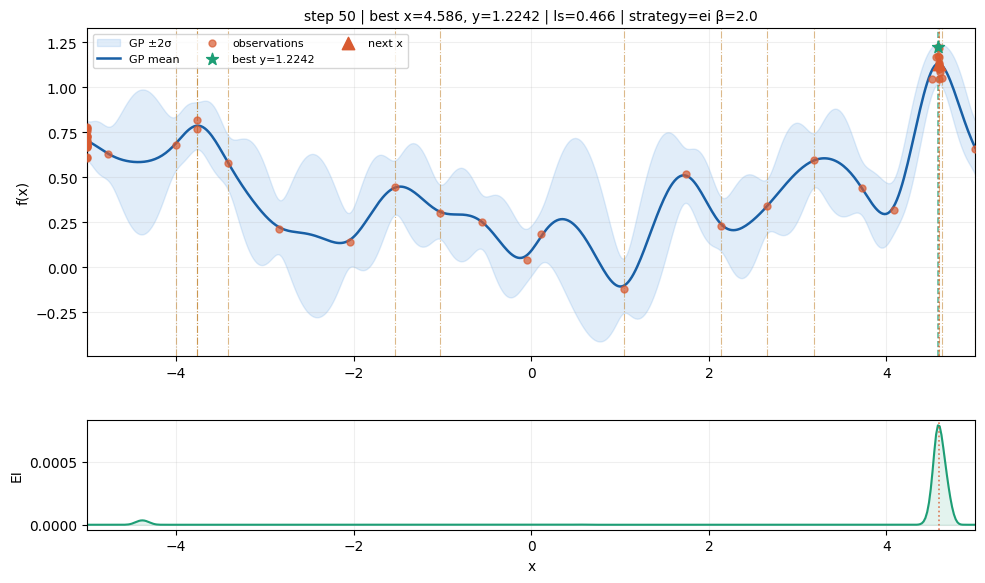

t= 49 | x=+4.587 | y=+1.1334 | μ=+1.1324 | σ=0.0564 | ls=0.466 | best=1.2242


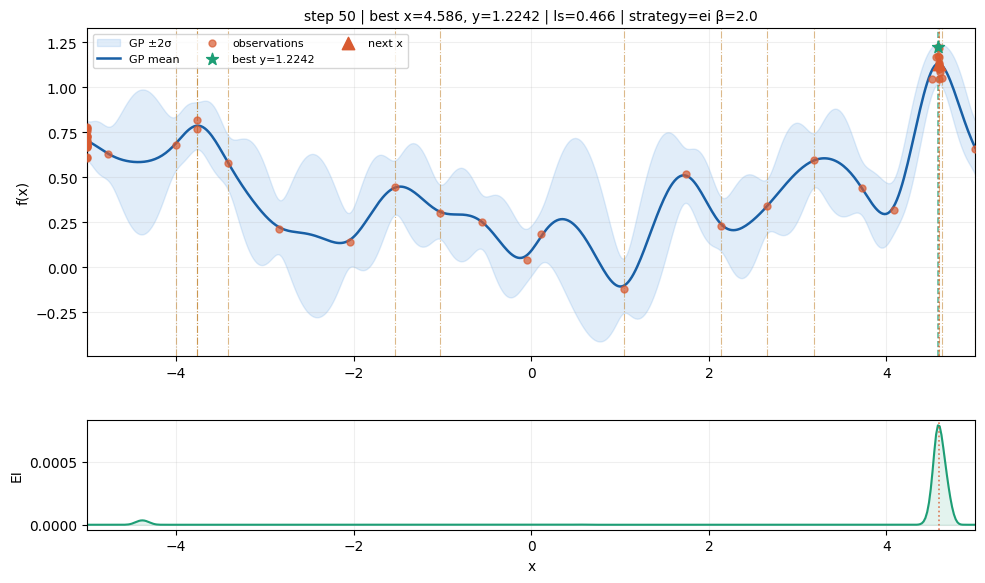

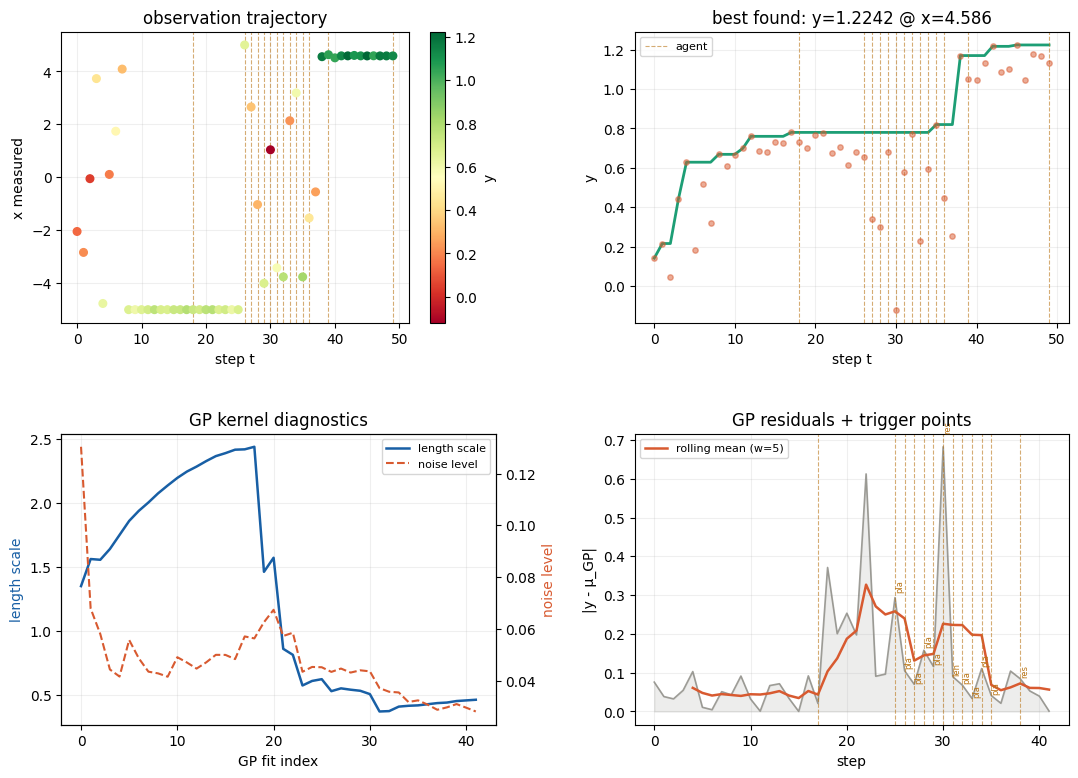

saved → campaign_analysis.png
{'best_x': 4.5862, 'best_y': 1.2242, 'n_obs': 50, 'agent_interventions': 14, 'agent_log': [{'step': 18, 'triggers': [], 'message': 'Length scale steadily increasing suggests the GP is smoothing over local features. Residuals are moderate but the best_x is at the boundary (-5.0), indicating we may be missing interior optima. Slightly increasing beta to encourage more exploration across the domain.'}, {'step': 26, 'triggers': ['plateau'], 'message': 'Plateau triggered with 48% budget remaining. Switching to pure uncertainty sampling (sigma) to force exploration of under-sampled regions. The GP residuals are low indicating good fit, but we may be stuck in a local area around x=-5.'}, {'step': 27, 'triggers': ['plateau'], 'message': 'Plateau triggered with 46% budget remaining. The recent residual spike (0.37) suggests unexplored regions. Switching from sigma to UCB with increased beta to drive more systematic exploration before exploiting.'}, {'step': 28, 'tr

In [45]:
# full run with agent
campaign = ExperimentalCampaign(sim_decay, x_bounds=(-5.0, 5.0))
gp       = GPSurrogate(window=50, length_scale=2.0)
acq      = AcquisitionFunction(x_bounds=(-5.0, 5.0))

loop = BOLoop(
    campaign=campaign,
    gp=gp,
    acquisition=acq,
    budget=50,
    n_init=8,
    agent_every=10,
    agent_callback=agent_callback,
    verbose=True,
)

report = loop.run()
post_analysis(report, campaign, gp)
print(report)
print("\n--- agent log ---")
for entry in report["agent_log"]:
    print(f"  t={entry['step']} | triggers={entry['triggers']}")
    print(f"  → {entry['message']}")

#benchmarking


In [46]:
#@title step7_benchmark.py
import numpy as np
import matplotlib.pyplot as plt
from copy import deepcopy
from dataclasses import dataclass


@dataclass
class RunResult:
    run_id: int
    method: str
    best_y: float
    best_x: float
    best_y_trajectory: list[float]   # best-so-far at each step
    n_obs: int
    agent_log: list[dict]


def run_single(method: str, run_id: int, simulator_factory, budget=50, n_init=8,
               agent_callback=None, verbose=False) -> RunResult:
    """
    One independent run of either 'agent_bo' or 'classical_bo'.
    simulator_factory() must return a fresh MeasurementSimulator each call
    so runs are independent but use the same ground truth.
    """
    sim = simulator_factory(seed=run_id)   # different rng seed per run

    campaign = ExperimentalCampaign(sim, x_bounds=(-5.0, 5.0))
    gp       = GPSurrogate(window=50, length_scale=2.0)
    acq      = AcquisitionFunction(x_bounds=(-5.0, 5.0))

    cb = agent_callback if method == "agent_bo" else None

    loop = BOLoop(
        campaign=campaign,
        gp=gp,
        acquisition=acq,
        budget=budget,
        n_init=n_init,
        agent_every=10,
        agent_callback=cb,
        verbose=verbose,
    )
    report = loop.run()

    # build best-so-far trajectory
    _, _, Y = campaign.observations
    trajectory = np.maximum.accumulate(Y).tolist()

    return RunResult(
        run_id=run_id,
        method=method,
        best_y=report["best_y"],
        best_x=report["best_x"],
        best_y_trajectory=trajectory,
        n_obs=report["n_obs"],
        agent_log=report["agent_log"],
    )


def benchmark(simulator_factory, agent_callback, n_runs=5, budget=50, n_init=8):
    """
    Runs n_runs of both methods and returns all RunResult objects.
    """
    results = {"agent_bo": [], "classical_bo": []}

    for run_id in range(n_runs):
        print(f"\n{'='*50}")
        print(f"run {run_id+1}/{n_runs}")

        for method in ["classical_bo", "agent_bo"]:
            print(f"  → {method} ...", end=" ", flush=True)
            r = run_single(
                method=method,
                run_id=run_id,
                simulator_factory=simulator_factory,
                budget=budget,
                n_init=n_init,
                agent_callback=agent_callback,
                verbose=False,
            )
            results[method].append(r)
            print(f"best_y={r.best_y:.4f}")

    return results


def plot_benchmark(results: dict):
    """
    Two-panel figure:
      Left:  best_y per run, side-by-side bars
      Right: mean best-so-far trajectory ± std
    """
    methods  = ["classical_bo", "agent_bo"]
    colors   = {"classical_bo": "#378ADD", "agent_bo": "#1D9E75"}
    labels   = {"classical_bo": "Classical BO (UCB β=2)", "agent_bo": "Agent BO"}

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

    # ── left: per-run bar chart ───────────────────────────────────────────────
    n_runs = len(results["classical_bo"])
    x      = np.arange(n_runs)
    w      = 0.35

    for i, method in enumerate(methods):
        ys = [r.best_y for r in results[method]]
        ax1.bar(x + i*w, ys, w, color=colors[method], alpha=0.8, label=labels[method])
        # mean line
        ax1.axhline(np.mean(ys), color=colors[method], lw=1.5, ls="--", alpha=0.7)

    ax1.set_xticks(x + w/2)
    ax1.set_xticklabels([f"run {i+1}" for i in range(n_runs)])
    ax1.set_ylabel("best y found")
    ax1.set_title("best y per run")
    ax1.legend(fontsize=9)
    ax1.grid(True, alpha=0.2, axis="y")

    # ── right: trajectory mean ± std ─────────────────────────────────────────
    for method in methods:
        trajs = [r.best_y_trajectory for r in results[method]]
        # pad to same length
        max_len = max(len(t) for t in trajs)
        padded  = [t + [t[-1]] * (max_len - len(t)) for t in trajs]
        arr     = np.array(padded)
        mean    = arr.mean(axis=0)
        std     = arr.std(axis=0)
        steps   = np.arange(max_len)

        ax2.plot(steps, mean, color=colors[method], lw=2, label=labels[method])
        ax2.fill_between(steps, mean - std, mean + std,
                         color=colors[method], alpha=0.15)

    ax2.set_xlabel("step")
    ax2.set_ylabel("best y found so far")
    ax2.set_title("convergence trajectory (mean ± std)")
    ax2.legend(fontsize=9)
    ax2.grid(True, alpha=0.2)

    # ── summary stats ─────────────────────────────────────────────────────────
    for method in methods:
        ys = [r.best_y for r in results[method]]
        n_int = np.mean([len(r.agent_log) for r in results[method]])
        print(f"{labels[method]:30s}  "
              f"mean={np.mean(ys):.4f}  std={np.std(ys):.4f}  "
              f"max={np.max(ys):.4f}  min={np.min(ys):.4f}  "
              f"agent_calls={n_int:.1f}")

    fig.suptitle("benchmark: agent BO vs classical BO", fontsize=12)
    fig.tight_layout()
    plt.savefig("benchmark.png", dpi=150, bbox_inches="tight")
    plt.show()
    print("saved → benchmark.png")

In [47]:
def simulator_factory(seed: int) -> MeasurementSimulator:
    return MeasurementSimulator(
        ground_truth_model=multimodal,
        noise_model=noise_decay_floor,
        rng=seed,
    )

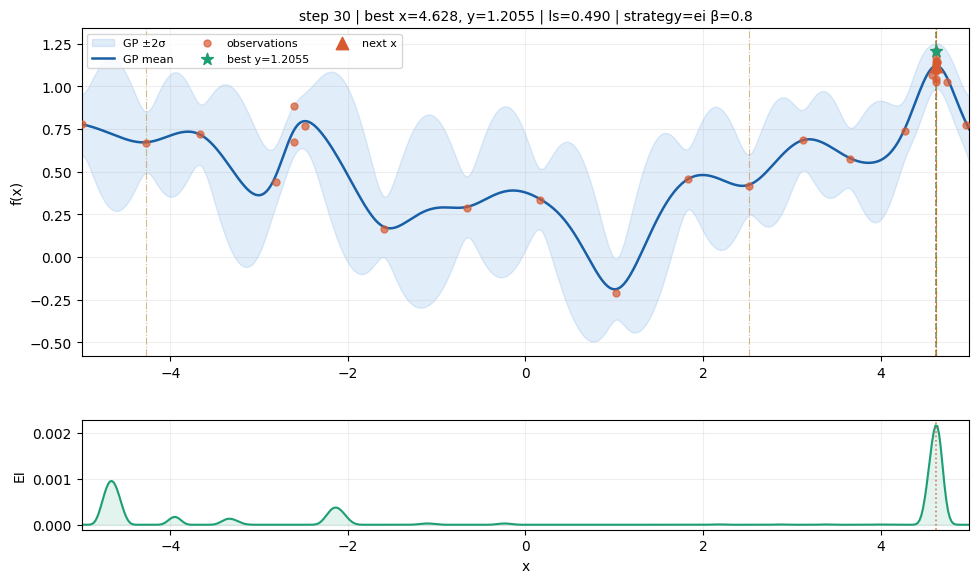

best_y=1.2055
Classical BO (UCB β=2)          mean=1.2165  std=0.0188  max=1.2408  min=1.1946  agent_calls=0.0
Agent BO                        mean=1.2217  std=0.0168  max=1.2469  min=1.2055  agent_calls=9.2


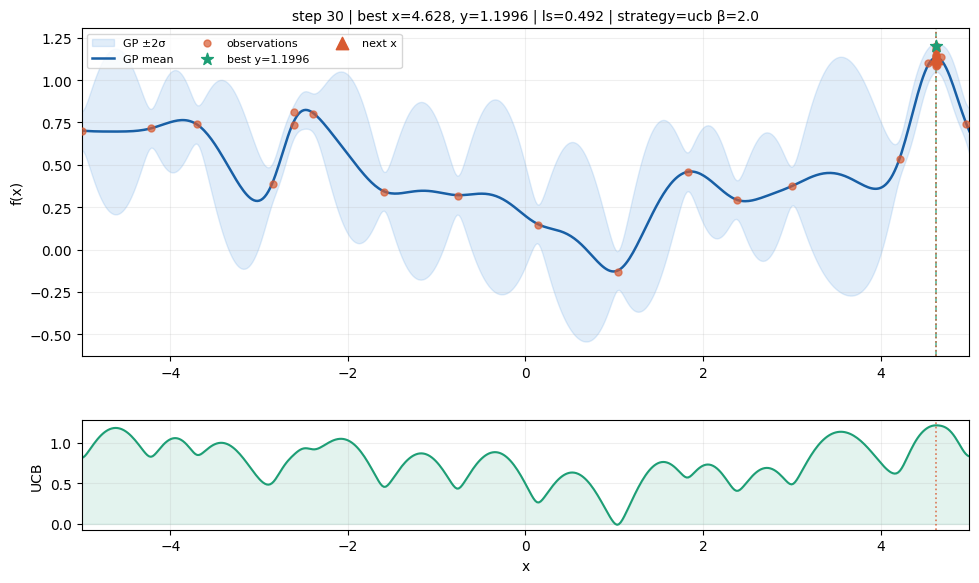

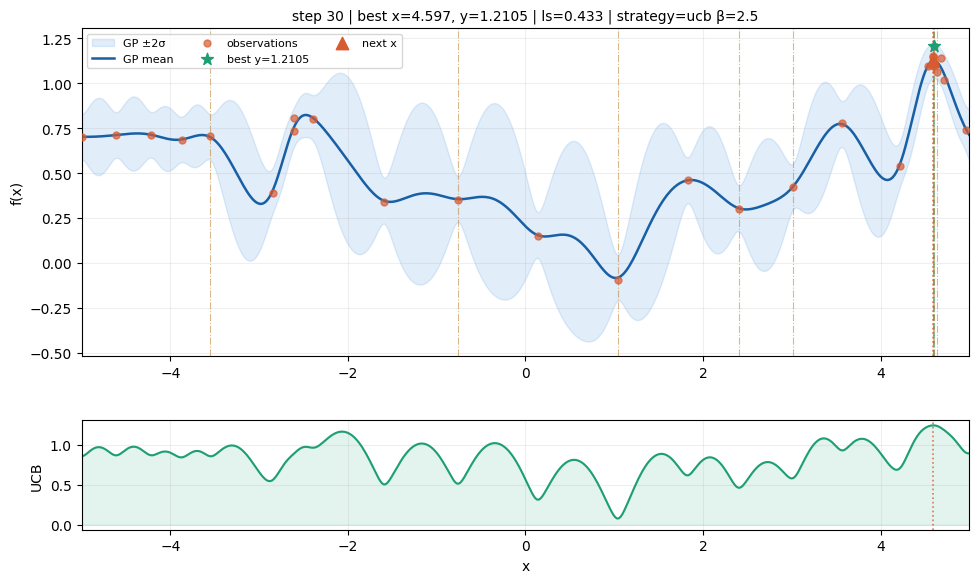

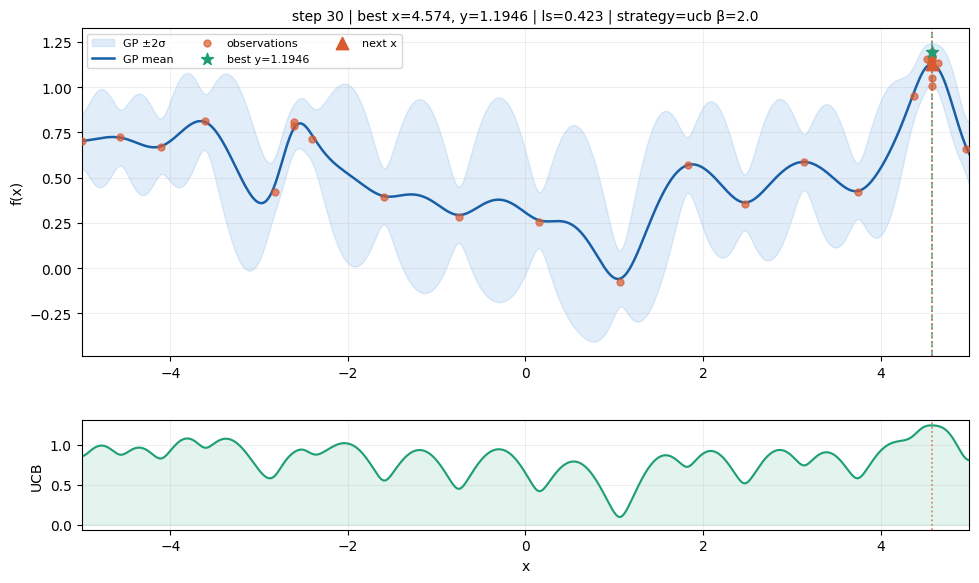

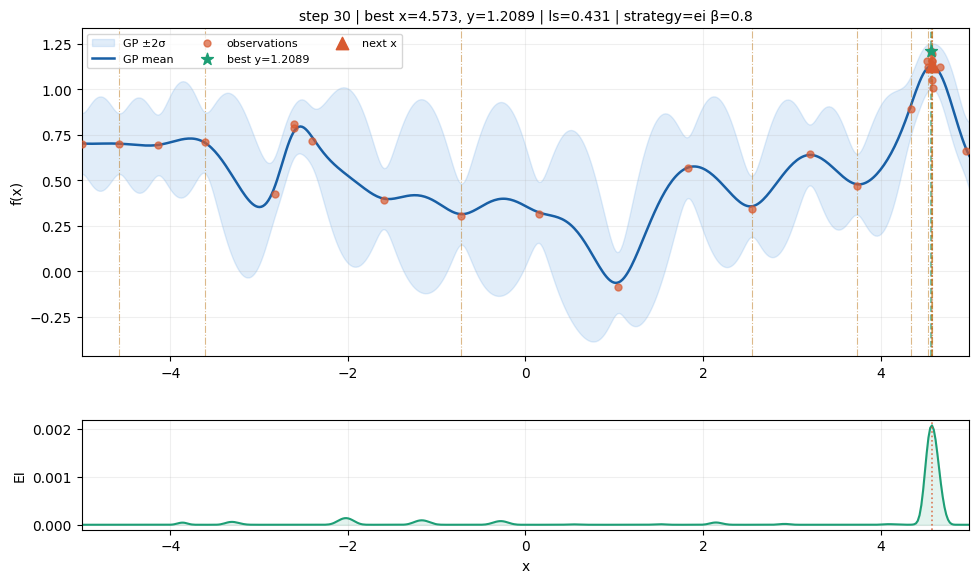

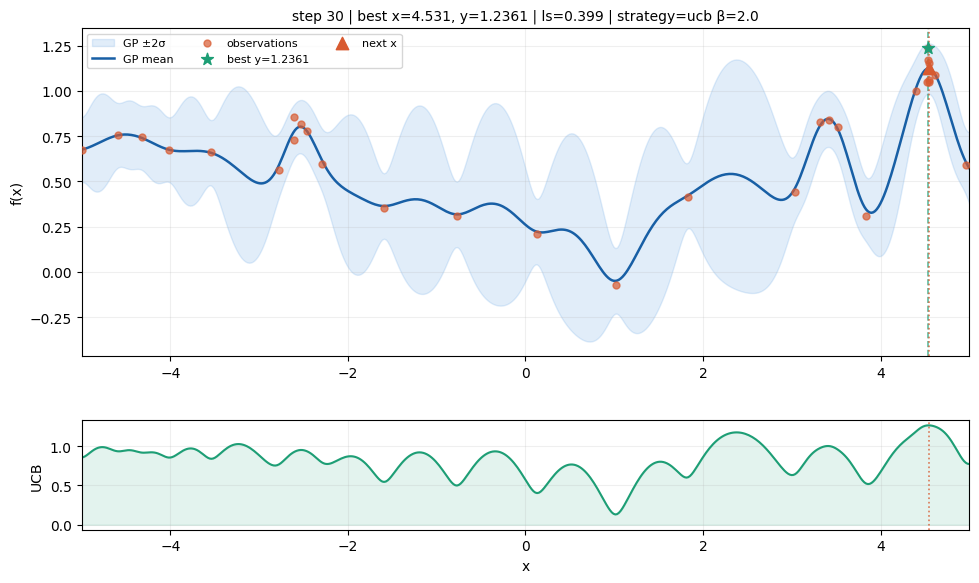

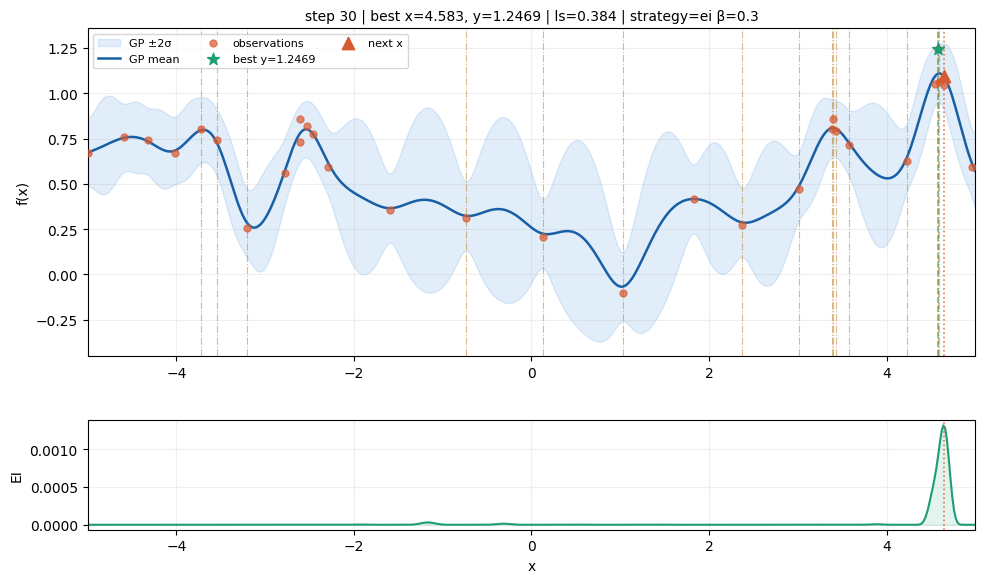

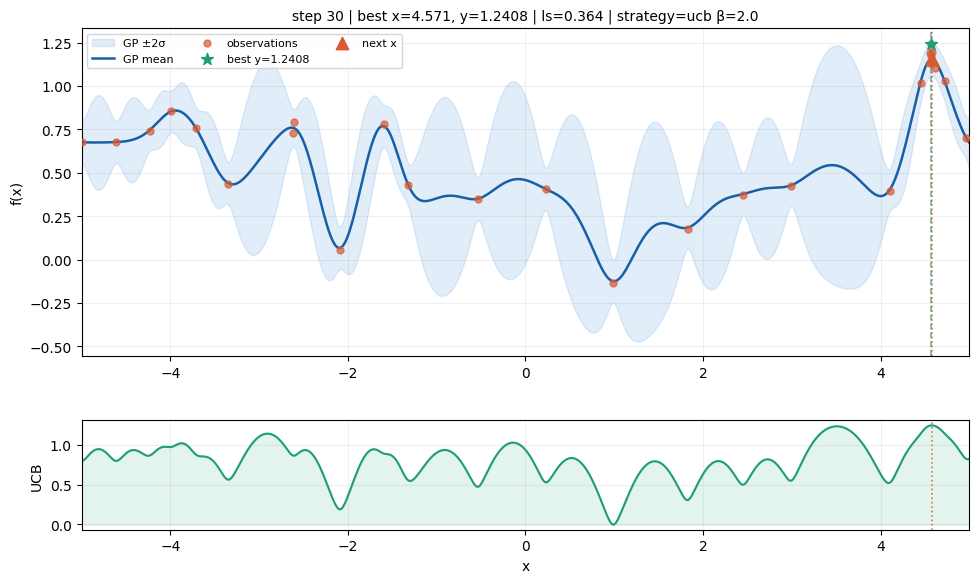

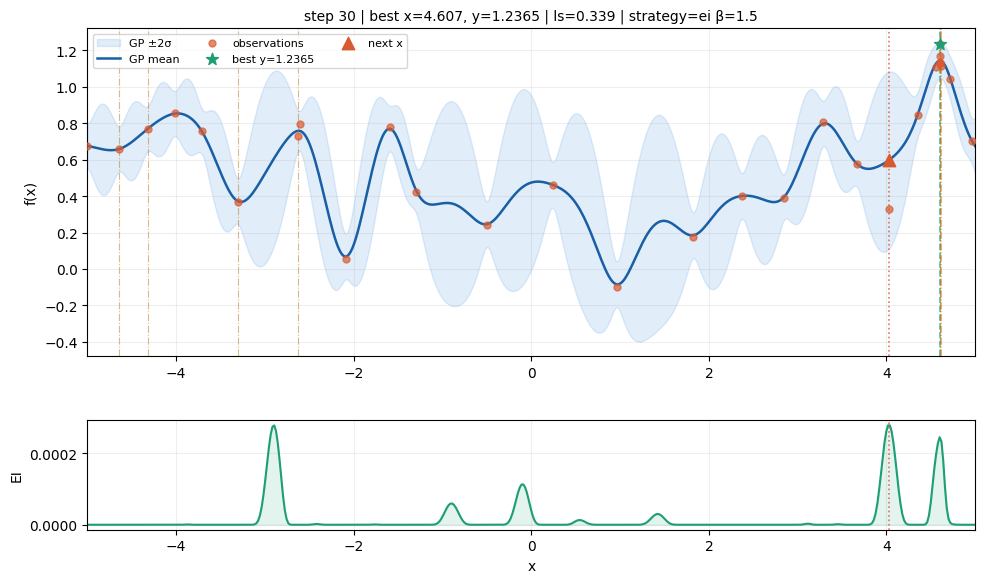

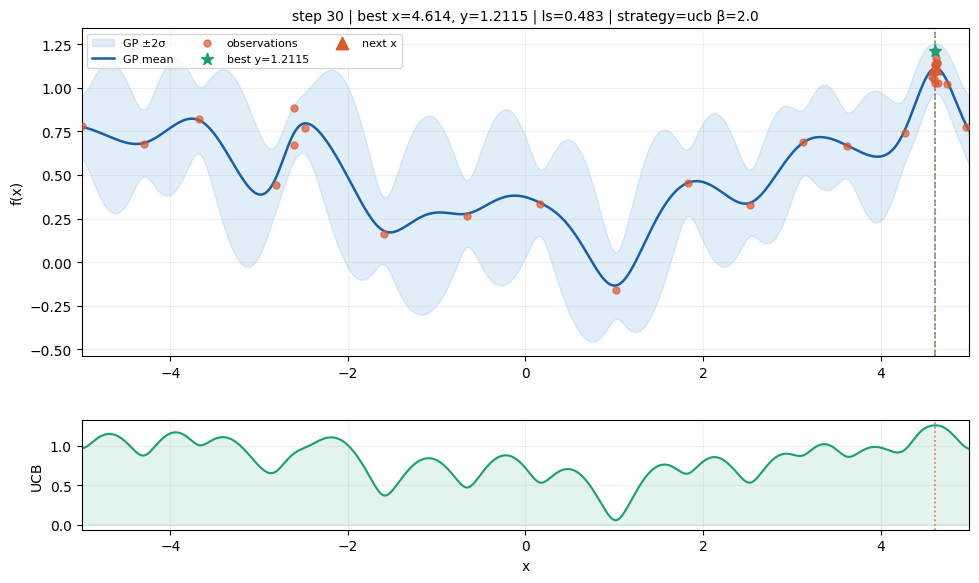

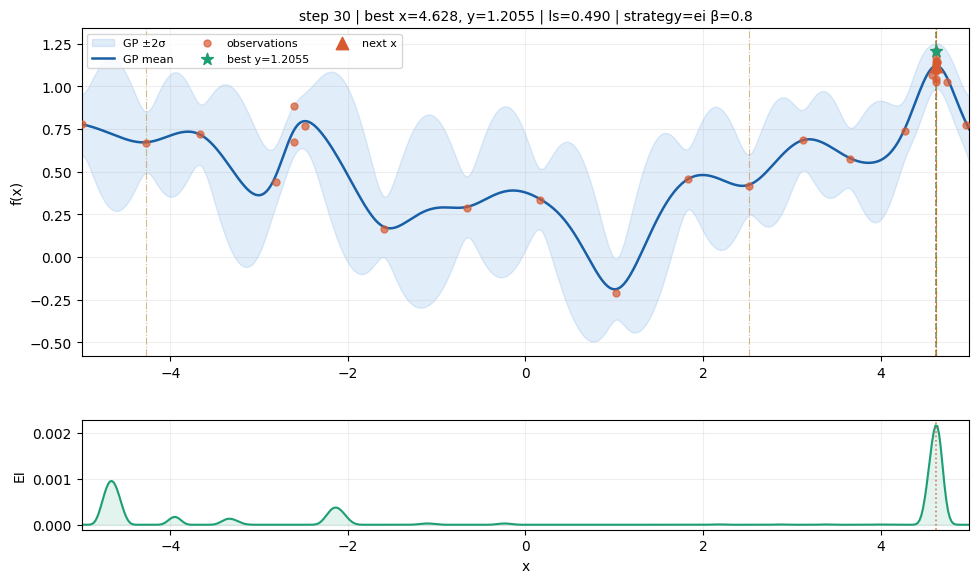

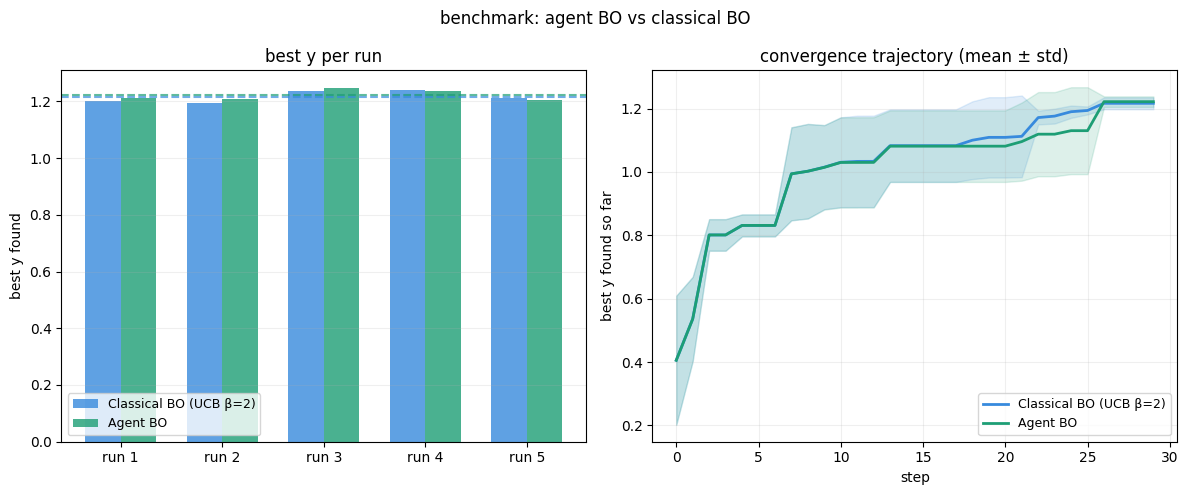

saved → benchmark.png


In [50]:
results = benchmark(
    simulator_factory=simulator_factory,
    agent_callback=agent_callback,
    n_runs=5,
    budget=30,
    n_init=4,
)

plot_benchmark(results)

In [57]:
def simulator_factory(seed: int) -> MeasurementSimulator:
    return MeasurementSimulator(
        ground_truth_model=broad_narrow,
        noise_model=noise_decay_floor,
        rng=seed,
    )

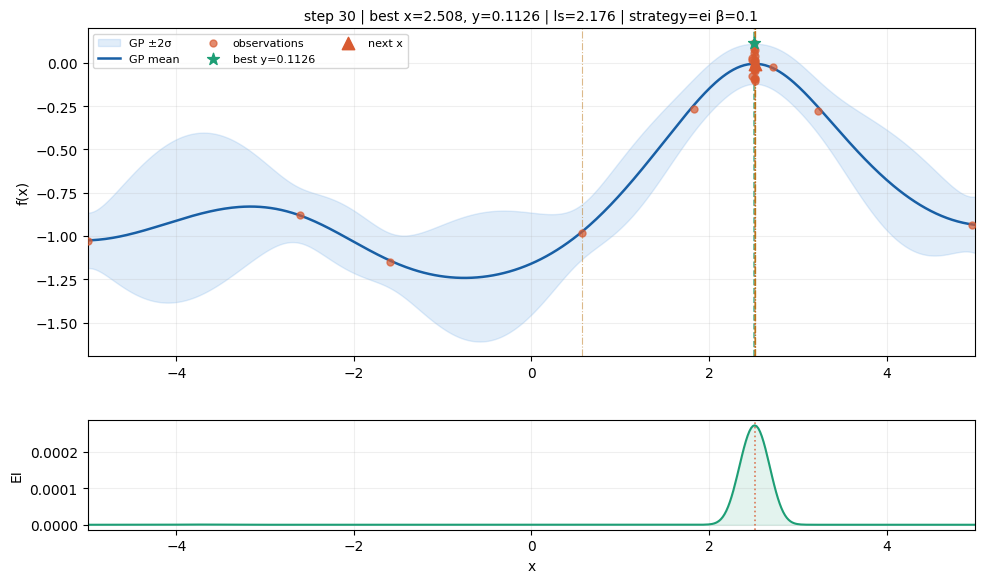

best_y=0.1126
Classical BO (UCB β=2)          mean=0.4300  std=0.3789  max=0.9179  min=0.1008  agent_calls=0.0
Agent BO                        mean=0.4200  std=0.3756  max=0.8993  min=0.1025  agent_calls=12.0


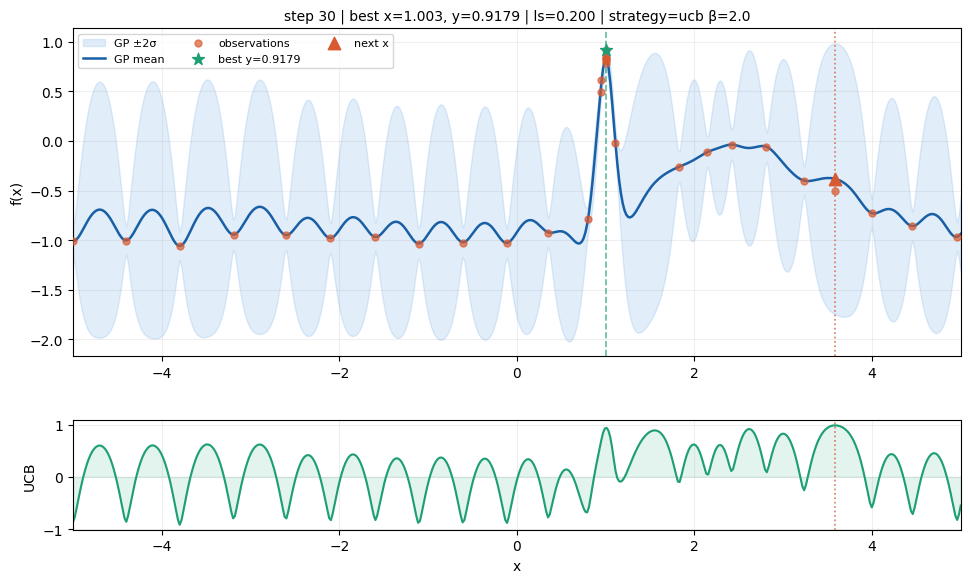

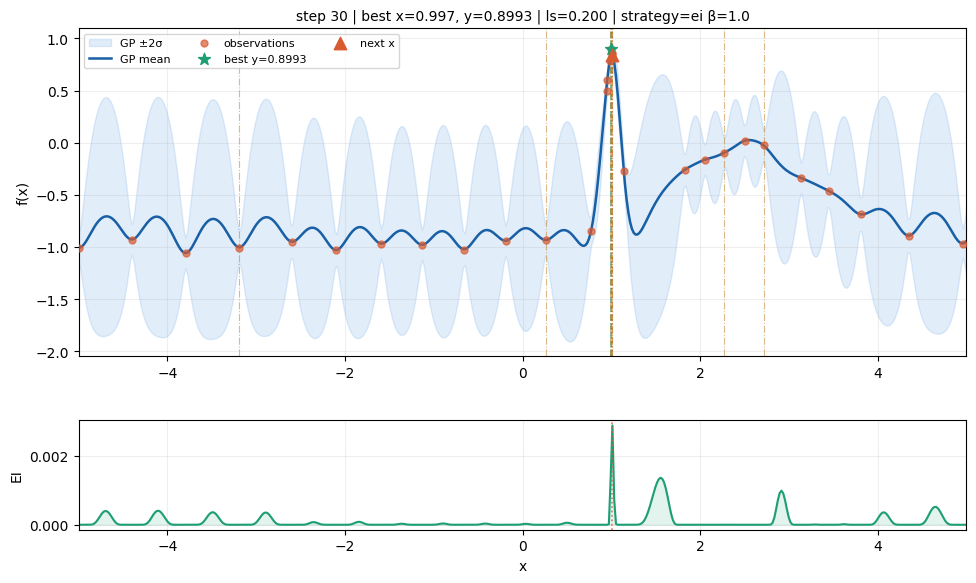

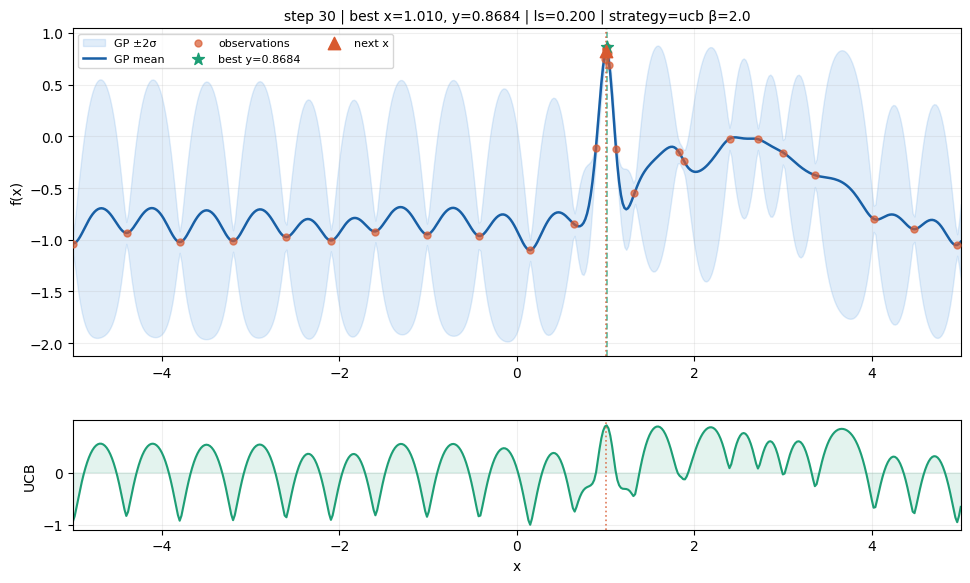

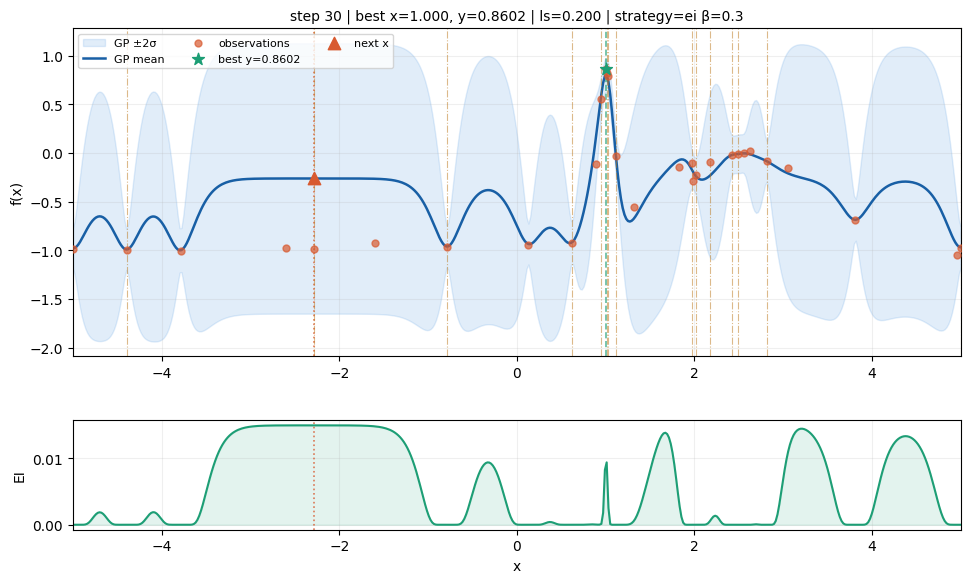

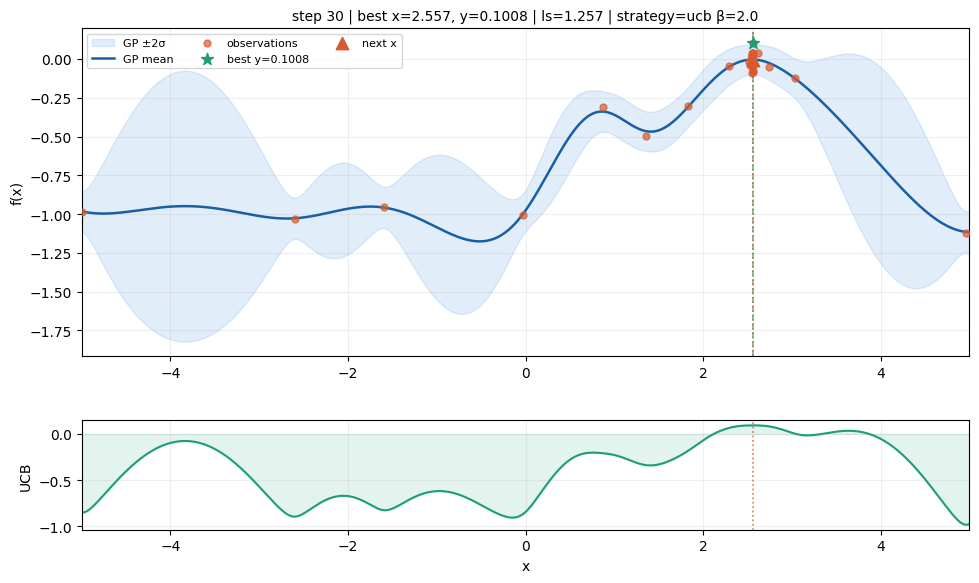

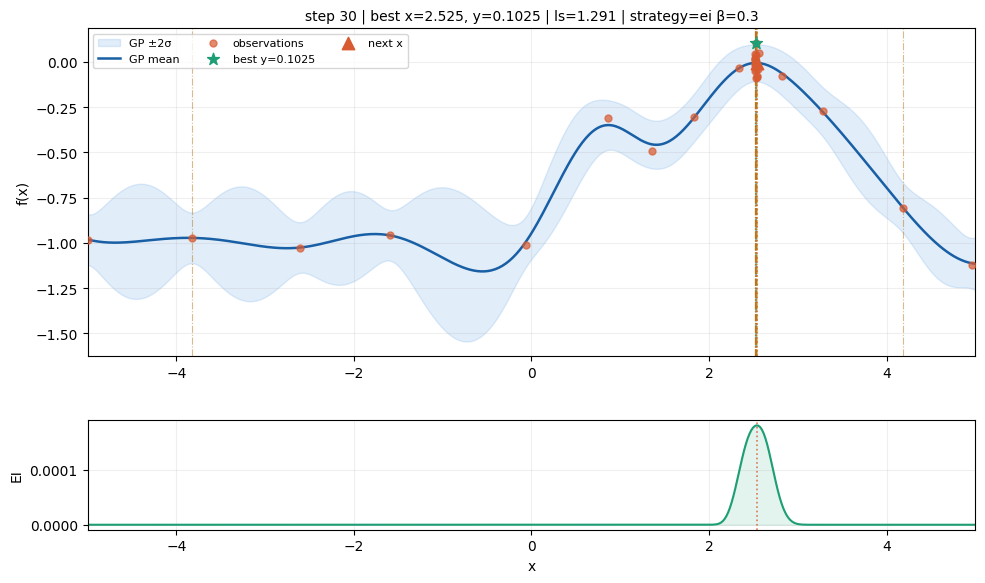

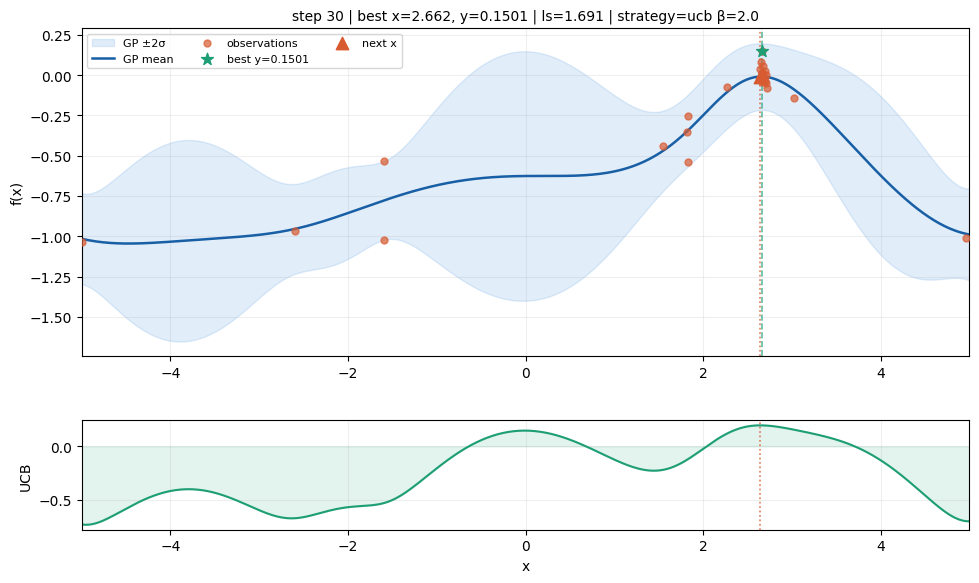

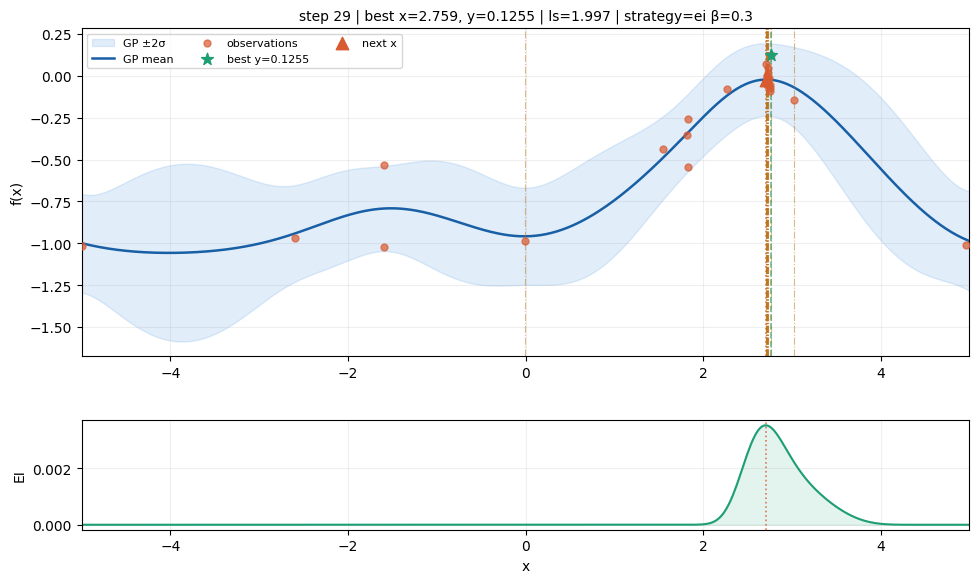

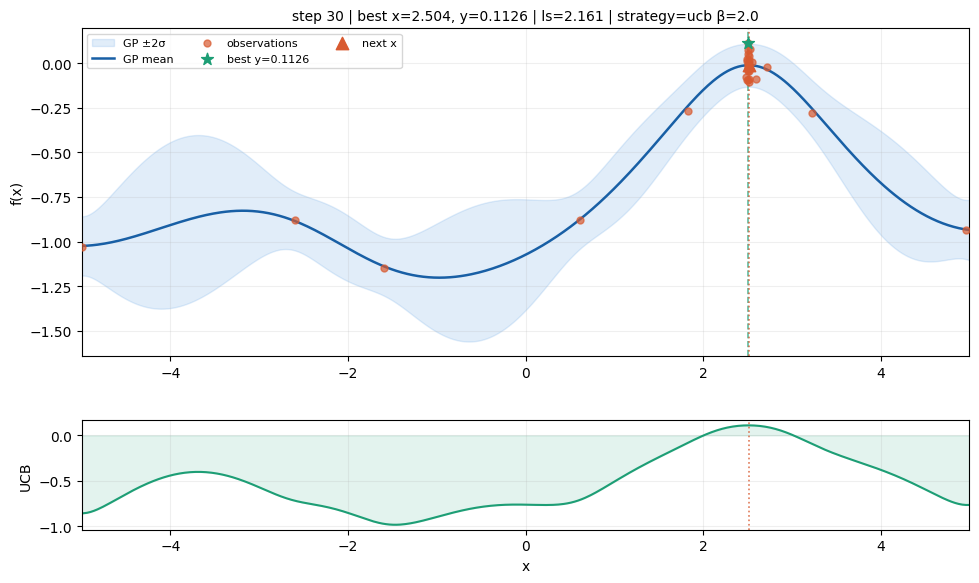

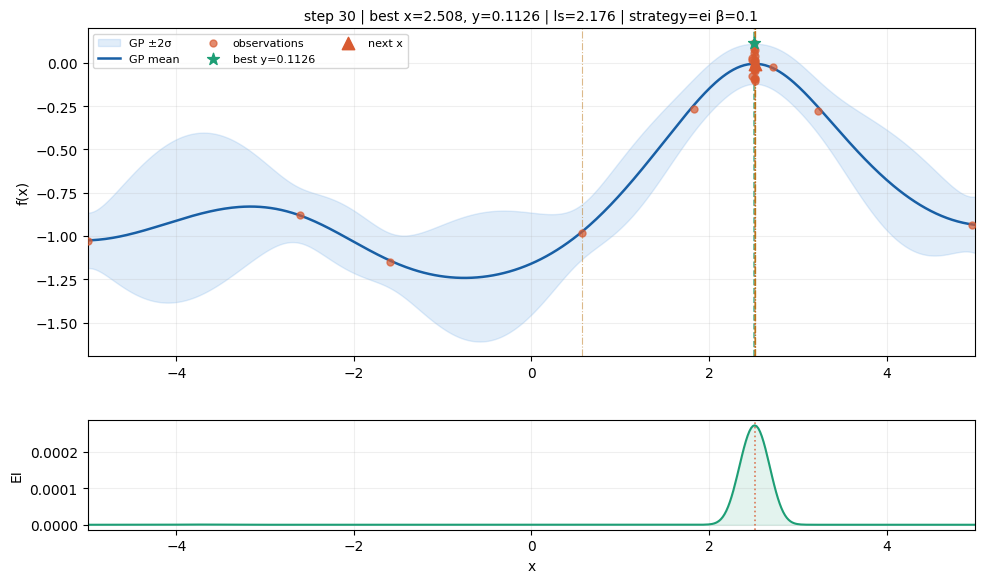

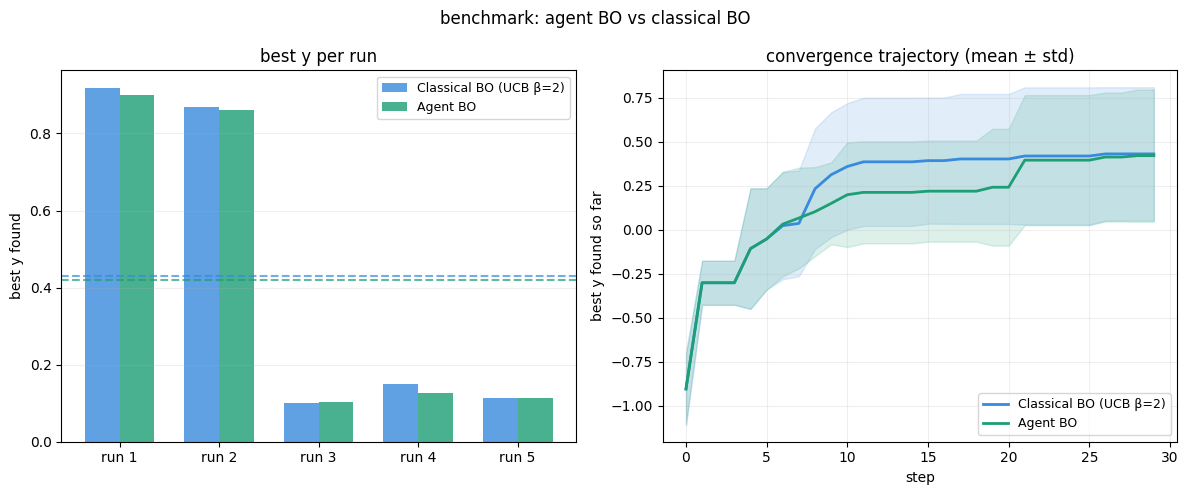

saved → benchmark.png


In [58]:
results = benchmark(
    simulator_factory=simulator_factory,
    agent_callback=agent_callback,
    n_runs=5,
    budget=30,
    n_init=4,
)

plot_benchmark(results)

In [60]:
#@title step8_coverage.py
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import entropy as scipy_entropy


# ── coverage metrics ──────────────────────────────────────────────────────────

def coverage_epsilon(X: np.ndarray, x_bounds=(-5.0, 5.0),
                     n_grid=500, eps=0.2) -> np.ndarray:
    """
    At each step t, fraction of x_grid within eps of any observation so far.
    Returns array of shape (len(X),).
    """
    grid = np.linspace(*x_bounds, n_grid)
    covered = np.zeros(len(X))
    for t in range(1, len(X) + 1):
        obs = X[:t]
        dists = np.abs(grid[:, None] - obs[None, :])   # (n_grid, t)
        covered[t-1] = np.mean(dists.min(axis=1) < eps)
    return covered


def coverage_entropy(X: np.ndarray, x_bounds=(-5.0, 5.0),
                     n_bins=20) -> np.ndarray:
    """
    At each step t, normalized Shannon entropy of the observation histogram.
    Max entropy = log(n_bins) when observations are perfectly uniform.
    Returns array of shape (len(X),) in [0, 1].
    """
    bins = np.linspace(*x_bounds, n_bins + 1)
    max_h = np.log(n_bins)
    entropies = np.zeros(len(X))
    for t in range(1, len(X) + 1):
        counts, _ = np.histogram(X[:t], bins=bins)
        counts = counts + 1e-9          # avoid log(0)
        h = scipy_entropy(counts)
        entropies[t-1] = h / max_h
    return entropies


def compute_coverage_trajectories(results: dict,
                                   x_bounds=(-5.0, 5.0),
                                   eps=0.2, n_bins=20) -> dict:
    """
    For each method and run, compute both coverage metrics vs step.
    Returns nested dict: coverage[method][metric] = list of arrays (one per run).
    """
    coverage = {}
    for method, runs in results.items():
        coverage[method] = {"epsilon": [], "entropy": []}
        for r in runs:
            X = np.array(r.best_y_trajectory)   # same length as observations
            # need raw X from campaign — store it in RunResult
            X_obs = np.array(r.X_obs)
            coverage[method]["epsilon"].append(
                coverage_epsilon(X_obs, x_bounds=x_bounds, eps=eps)
            )
            coverage[method]["entropy"].append(
                coverage_entropy(X_obs, x_bounds=x_bounds, n_bins=n_bins)
            )
    return coverage


# ── extended RunResult ────────────────────────────────────────────────────────
# Add X_obs to RunResult and run_single so coverage has raw coordinates.

from dataclasses import dataclass, field

@dataclass
class RunResult:
    run_id: int
    method: str
    best_y: float
    best_x: float
    best_y_trajectory: list[float]
    X_obs: list[float]              # raw x coordinates in order measured
    n_obs: int
    agent_log: list[dict]


def run_single(method, run_id, simulator_factory, budget=50, n_init=8,
               agent_callback=None, verbose=False) -> RunResult:
    sim      = simulator_factory(seed=run_id)
    campaign = ExperimentalCampaign(sim, x_bounds=(-5.0, 5.0))
    gp       = GPSurrogate(window=50, length_scale=2.0)
    acq      = AcquisitionFunction(x_bounds=(-5.0, 5.0))
    cb       = agent_callback if method == "agent_bo" else None

    loop = BOLoop(
        campaign=campaign, gp=gp, acquisition=acq,
        budget=budget, n_init=n_init, agent_every=10,
        agent_callback=cb, verbose=verbose,
    )
    report = loop.run()

    _, _, Y = campaign.observations
    trajectory = np.maximum.accumulate(Y).tolist()

    return RunResult(
        run_id=run_id,
        method=method,
        best_y=report["best_y"],
        best_x=report["best_x"],
        best_y_trajectory=trajectory,
        X_obs=list(campaign.X),         # raw coordinates
        n_obs=report["n_obs"],
        agent_log=report["agent_log"],
    )


# ── full benchmark plot ───────────────────────────────────────────────────────

def plot_benchmark_full(results: dict, x_bounds=(-5.0, 5.0), eps=0.2, n_bins=20):
    """
    2×2 figure:
      [0,0] best y per run (bars)
      [0,1] convergence trajectory mean ± std
      [1,0] epsilon-coverage vs step mean ± std
      [1,1] entropy-coverage vs step mean ± std
    """
    methods = ["classical_bo", "agent_bo"]
    colors  = {"classical_bo": "#378ADD", "agent_bo": "#1D9E75"}
    labels  = {"classical_bo": "Classical BO", "agent_bo": "Agent BO"}

    # precompute coverage
    cov = {}
    for method, runs in results.items():
        cov[method] = {"epsilon": [], "entropy": []}
        for r in runs:
            X_obs = np.array(r.X_obs)
            cov[method]["epsilon"].append(
                coverage_epsilon(X_obs, x_bounds=x_bounds, eps=eps)
            )
            cov[method]["entropy"].append(
                coverage_entropy(X_obs, x_bounds=x_bounds, n_bins=n_bins)
            )

    fig, axes = plt.subplots(2, 2, figsize=(13, 9))
    fig.suptitle("benchmark: agent BO vs classical BO", fontsize=12)

    # ── [0,0] best y bars ────────────────────────────────────────────────────
    ax = axes[0, 0]
    n_runs = len(results["classical_bo"])
    x      = np.arange(n_runs)
    w      = 0.35
    for i, method in enumerate(methods):
        ys = [r.best_y for r in results[method]]
        ax.bar(x + i*w, ys, w, color=colors[method], alpha=0.8, label=labels[method])
        ax.axhline(np.mean(ys), color=colors[method], lw=1.5, ls="--", alpha=0.7)
    ax.set_xticks(x + w/2)
    ax.set_xticklabels([f"run {i+1}" for i in range(n_runs)])
    ax.set_ylabel("best y found")
    ax.set_title("best y per run")
    ax.legend(fontsize=8)
    ax.grid(True, alpha=0.2, axis="y")

    # ── [0,1] convergence trajectory ─────────────────────────────────────────
    ax = axes[0, 1]
    for method in methods:
        trajs   = [r.best_y_trajectory for r in results[method]]
        max_len = max(len(t) for t in trajs)
        padded  = np.array([t + [t[-1]] * (max_len - len(t)) for t in trajs])
        mean, std = padded.mean(0), padded.std(0)
        steps = np.arange(max_len)
        ax.plot(steps, mean, color=colors[method], lw=2, label=labels[method])
        ax.fill_between(steps, mean - std, mean + std,
                        color=colors[method], alpha=0.15)
    ax.set_xlabel("step")
    ax.set_ylabel("best y so far")
    ax.set_title("convergence (mean ± std)")
    ax.legend(fontsize=8)
    ax.grid(True, alpha=0.2)

    # ── [1,0] epsilon coverage ────────────────────────────────────────────────
    ax = axes[1, 0]
    for method in methods:
        arrs    = cov[method]["epsilon"]
        max_len = max(len(a) for a in arrs)
        padded  = np.array([np.append(a, [a[-1]] * (max_len - len(a))) for a in arrs])
        mean, std = padded.mean(0), padded.std(0)
        steps = np.arange(max_len)
        ax.plot(steps, mean, color=colors[method], lw=2, label=labels[method])
        ax.fill_between(steps, mean - std, mean + std,
                        color=colors[method], alpha=0.15)
    ax.axhline(1.0, color="#888780", lw=0.8, ls="--", alpha=0.5)
    ax.set_xlabel("step")
    ax.set_ylabel(f"fraction covered (ε={eps})")
    ax.set_title(f"ε-coverage vs step  [ε={eps}]")
    ax.set_ylim(0, 1.05)
    ax.legend(fontsize=8)
    ax.grid(True, alpha=0.2)

    # ── [1,1] entropy coverage ────────────────────────────────────────────────
    ax = axes[1, 1]
    for method in methods:
        arrs    = cov[method]["entropy"]
        max_len = max(len(a) for a in arrs)
        padded  = np.array([np.append(a, [a[-1]] * (max_len - len(a))) for a in arrs])
        mean, std = padded.mean(0), padded.std(0)
        steps = np.arange(max_len)
        ax.plot(steps, mean, color=colors[method], lw=2, label=labels[method])
        ax.fill_between(steps, mean - std, mean + std,
                        color=colors[method], alpha=0.15)
    ax.axhline(1.0, color="#888780", lw=0.8, ls="--", alpha=0.5, label="uniform")
    ax.set_xlabel("step")
    ax.set_ylabel("normalized entropy")
    ax.set_title(f"observation entropy vs step  [{n_bins} bins]")
    ax.set_ylim(0, 1.05)
    ax.legend(fontsize=8)
    ax.grid(True, alpha=0.2)

    # ── summary table ─────────────────────────────────────────────────────────
    print(f"\n{'method':<22} {'best_y mean':>12} {'best_y std':>11} "
          f"{'final ε-cov':>12} {'final entropy':>14} {'agent calls':>12}")
    print("-" * 85)
    for method in methods:
        ys       = [r.best_y for r in results[method]]
        fin_eps  = np.mean([cov[method]["epsilon"][i][-1]
                            for i in range(len(results[method]))])
        fin_ent  = np.mean([cov[method]["entropy"][i][-1]
                            for i in range(len(results[method]))])
        n_int    = np.mean([len(r.agent_log) for r in results[method]])
        print(f"{labels[method]:<22} {np.mean(ys):>12.4f} {np.std(ys):>11.4f} "
              f"{fin_eps:>12.3f} {fin_ent:>14.3f} {n_int:>12.1f}")

    fig.tight_layout()
    plt.savefig("benchmark_full.png", dpi=150, bbox_inches="tight")
    plt.show()
    print("\nsaved → benchmark_full.png")

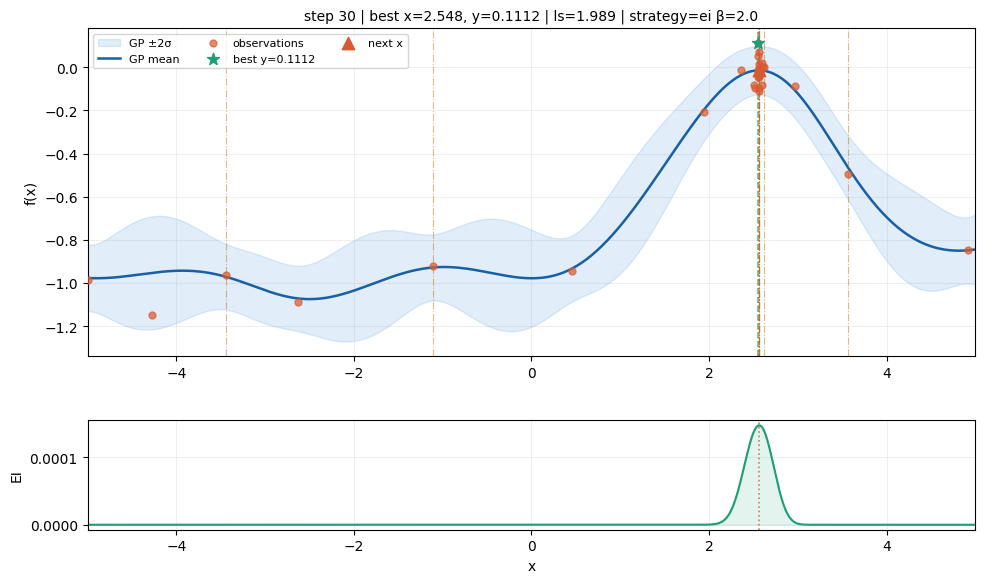

best_y=0.1112

method                  best_y mean  best_y std  final ε-cov  final entropy  agent calls
-------------------------------------------------------------------------------------
Classical BO                 0.0838      0.0166        0.323          0.354          0.0
Agent BO                     0.2428      0.3158        0.457          0.559          9.0


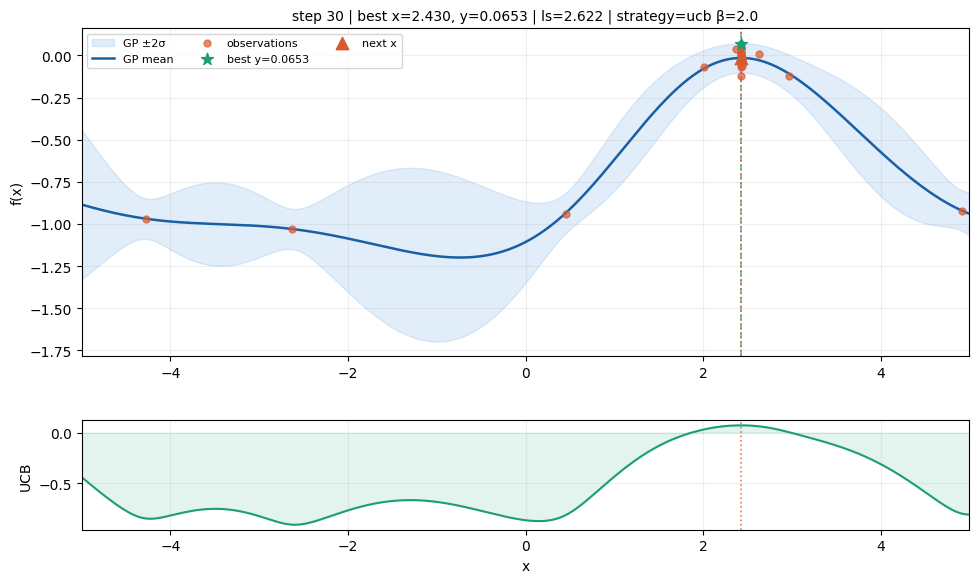

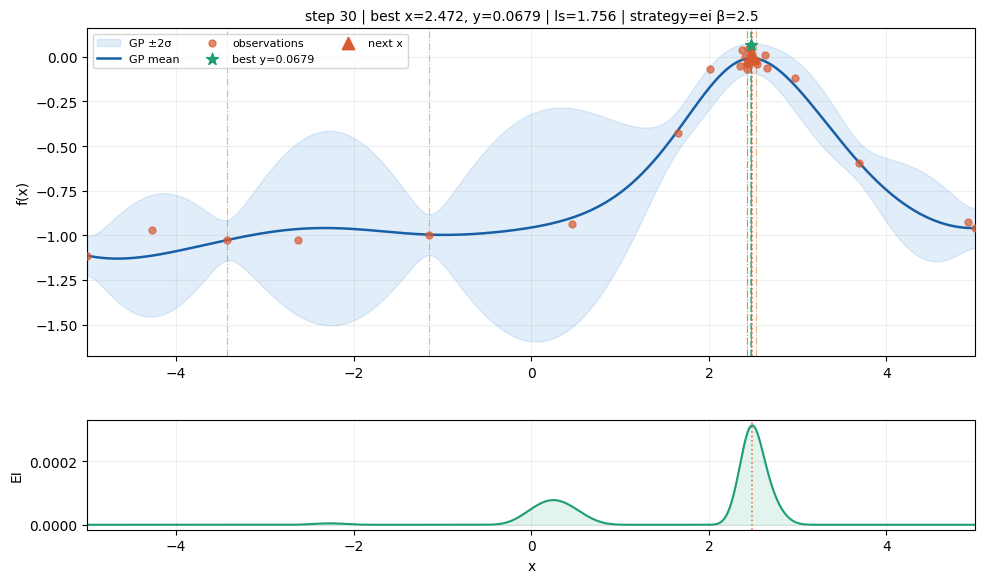

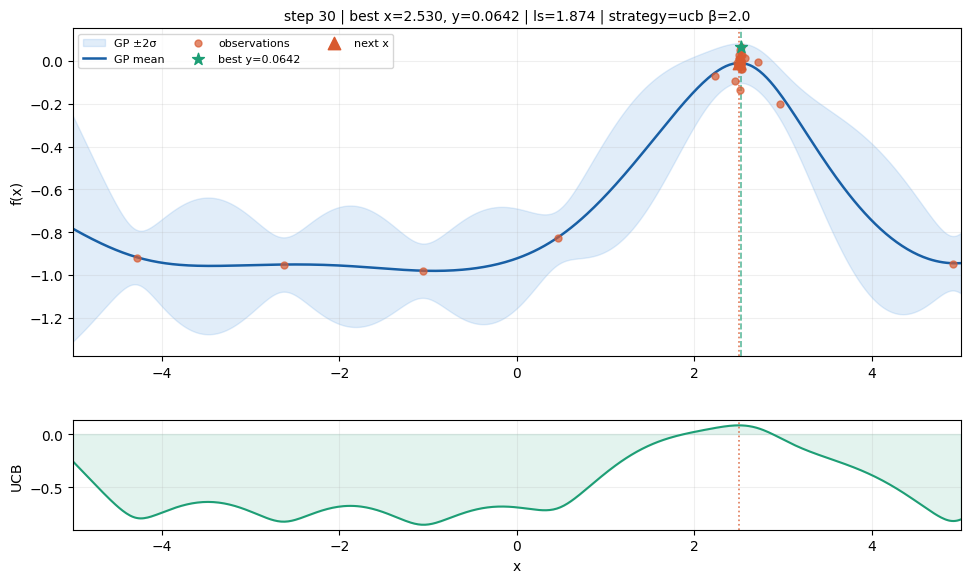

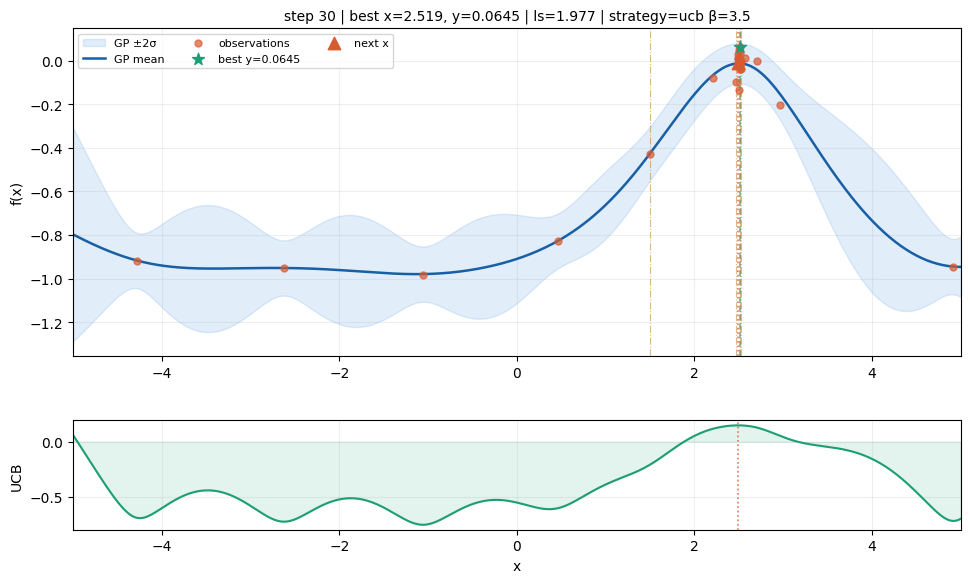

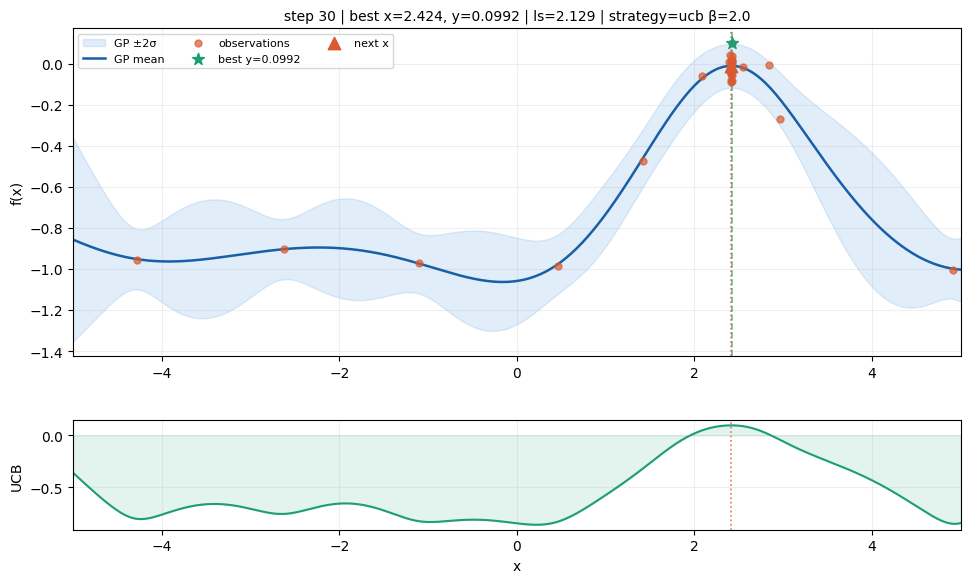

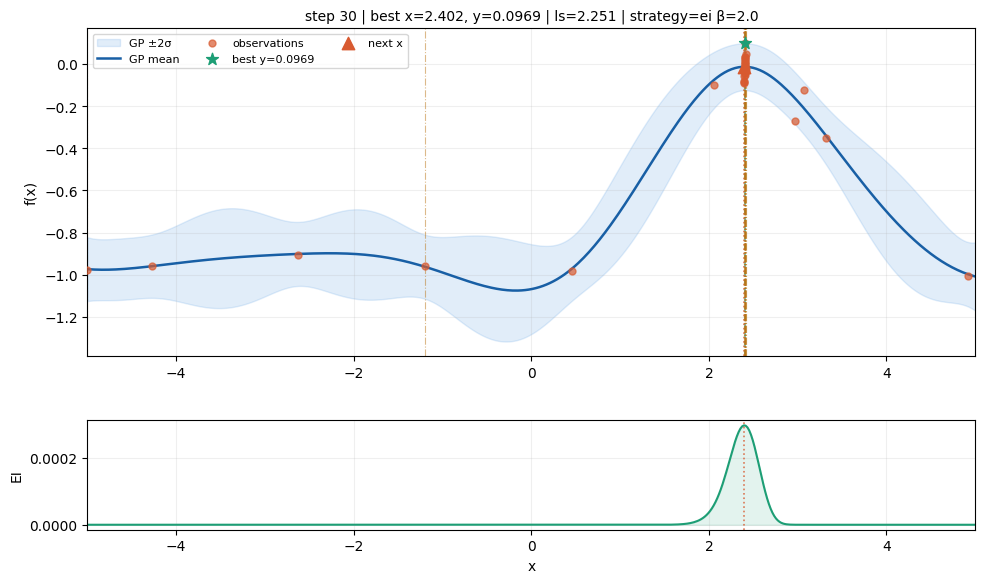

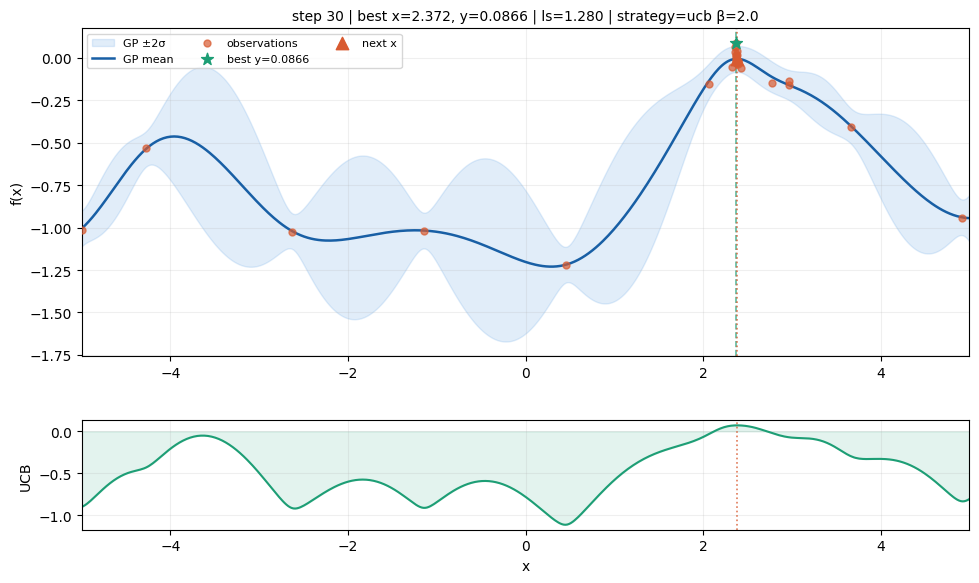

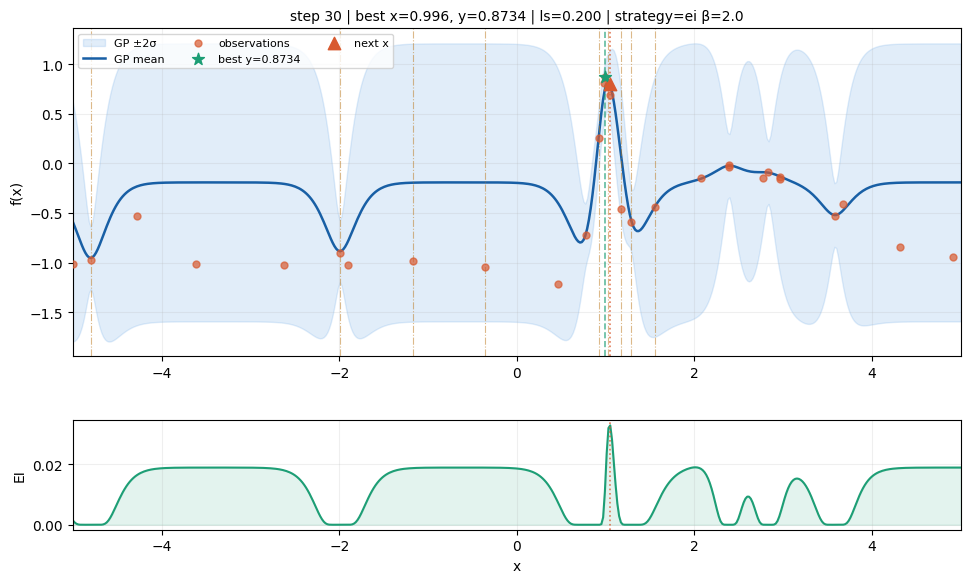

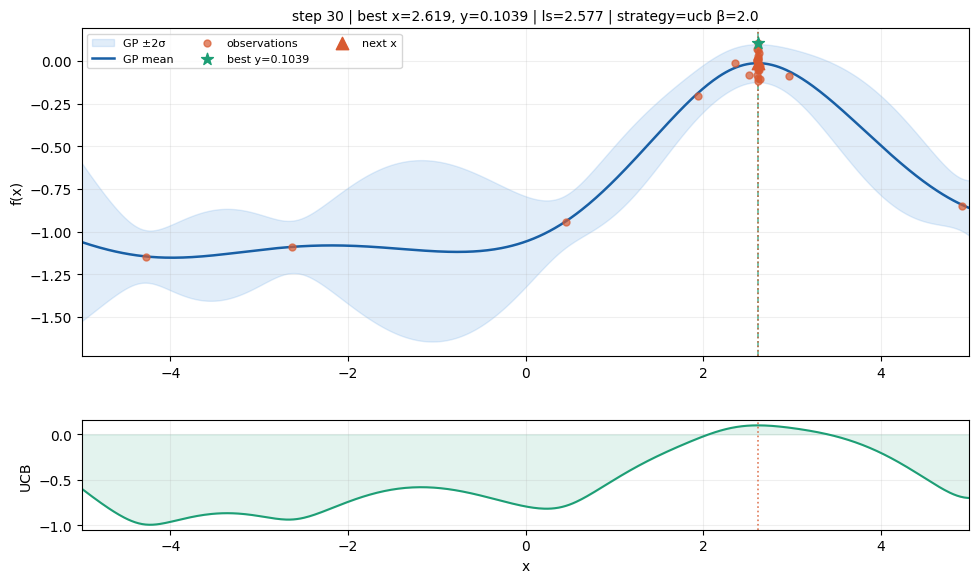

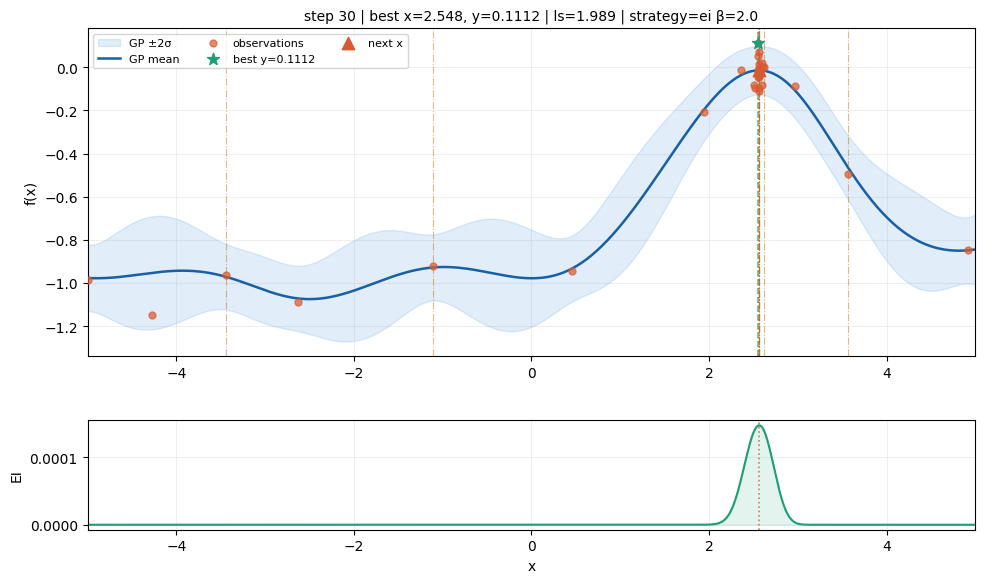

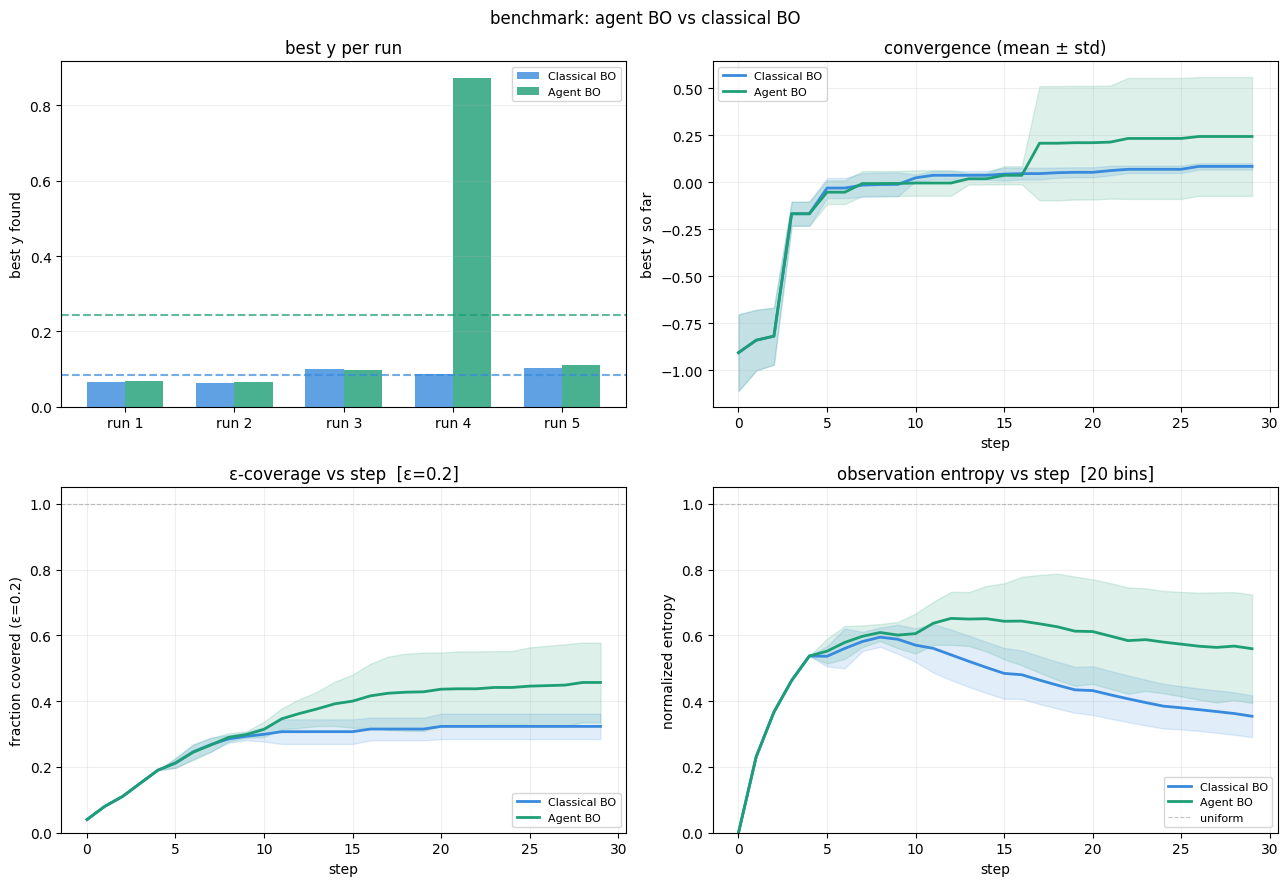


saved → benchmark_full.png


In [66]:
results = benchmark(
    simulator_factory=simulator_factory,
    agent_callback=agent_callback,
    n_runs=5,
    budget=30,
    n_init=5,
)

plot_benchmark_full(results, x_bounds=(-5.0, 5.0), eps=0.2, n_bins=20)